# 1. Título

**Saúde da Mulher na África Subsaariana**

Desigualdades entre países, residência, riqueza e escolaridade — TZ1 / DCC011

# 2. Membros (nome e número de matrícula)

| Integrante | Matrícula |
|---|---|
| Henrique Lima Gusmão | 2025014508 |
| Felipe Pires Franco | A informar |
| Izabella Galdino Correia | A informar |
| Alice Lina Oliveira da Silva | A informar |

# 3. Descrição, obtenção e processamento dos dados

O projeto utiliza microdados **DHS, originalmente distribuídos em Stata (.DTA)**, sobre saúde da mulher e condições de vida em **37 países da África Subsaariana**. O banco de preparação do repositório reúne **4.529.723 linhas em dez recodes**, incluindo **407.600 mulheres**, **877.412 nascidos vivos BR**, **385.457 domicílios HR**, **1.884.683 moradores PR** e **282.641 crianças KR**. Somar recodes não equivale a contar pessoas distintas.

O foco em saúde da mulher contempla o ponto extra temático. O núcleo normalizado deste trabalho é **IR/HR/PR/BR/KR**; os módulos complementares continuam no banco de preparação, pois sua fase pode diferir da pesquisa da mulher. Os 108 levantamentos do catálogo local não são 108 pesquisas de mulheres selecionadas: o IR contém uma pesquisa por país, em anos diferentes.

**Pergunta central:** quanto das diferenças de contracepção e pré-natal entre contextos rurais e urbanos se relaciona à composição de riqueza e escolaridade de cada país? Vamos comparar diferenças brutas e padronizadas, cobertura dos indicadores e heterogeneidade entre países. Não presumimos que um padrão continental descreve cada país nem que uma associação revela causalidade.

### 3.1 Como obter e reproduzir

1. Solicitar acesso aos países/levantamentos no [portal DHS](https://dhsprogram.com/data/Access-Instructions.cfm). Os microdados exigem autorização; o [catálogo de datasets da API](https://api.dhsprogram.com/rest/dhs/datasets) é público. Não registrar credenciais no notebook.
2. Instalar Git LFS antes de clonar o repositório indicado no README e instalar `requirements.txt`. Abrir o notebook em um editor compatível com Jupyter; as dependências de execução, gráficos e validação estão no arquivo de requisitos.
3. Usar o catálogo local e os scripts abaixo; a API/catalogação informa a origem, enquanto o manifesto registra arquivo, fase, variáveis e quantidade de linhas selecionadas.

```bash
python database_python/baixar_datasets.py --urls-file catalogo_datasets.csv --recode IR,BR,HR,PR,KR --extract --output-dir dados/completo
python database_python/preparar_dados_projeto.py --source dados/completo/extraidos --output dados/relevantes
python database_python/carregar_sqlite.py
```

Os argumentos/defaults do preparador devem corresponder ao caminho de extração adotado; seus defaults usam os dados completos locais. **Não usar `pd.read_csv` diretamente nos compactos consolidados**: a largura das linhas varia por país e o loader existente usa `manifesto_selecao.csv` para alinhá-las. O SQLite de origem é uma etapa de preparação dos arquivos Stata, não um dataset originalmente fornecido em SQL.

### 3.2 Construção bottom-up e normalização

Partimos dos recodes e dos dicionários; identificamos chaves e dependências funcionais; decompomos os atributos; carregamos as relações normalizadas; e mapeamos esse esquema para os diagramas ER/relacional das seções 4 e 5.

| Dependência identificada | Decomposição |
|---|---|
| Código do país → nome | Pais |
| Levantamento → país, fase | Levantamento |
| Levantamento + cluster + domicílio → contexto habitacional | Domicilio |
| Domicílio + linha da mulher → perfil individual | Mulher |
| Mulher → data, peso, coorte analítica e resposta contraceptiva da entrevista selecionada | Entrevista |
| Mulher + índice do nascimento → histórico de cada nascido vivo | Nascimento |
| Nascimento → acompanhamento infantil KR, quando disponível | Crianca |
| Domicílio + linha do morador → perfil do morador | Morador |
| Método → nome, classificação | Metodo |
| Mulher + método → nível de conhecimento | Conhecimento_Metodo |

**1FN:** atributos escalares e identificadores únicos; as nove colunas repetidas de conhecimento são transformadas em linhas Mulher–Método. **2FN:** o nível depende do par completo mulher–método, não apenas de um deles. **3FN:** nome do país, fase, contexto habitacional e nome/classificação do método ficam em suas próprias relações. As entidades filhas não repetem país/levantamento; esses dados são obtidos pelas FKs. Identificadores técnicos concatenados codificam as chaves naturais, e restrições `UNIQUE` as explicitam.

**Cuidados de integração:** `caseid` tem espaços incompatíveis em alguns recodes. Usamos `(levantamento, cluster, domicílio, linha)` para identificar a mulher, e acrescentamos `bidx` para o nascimento. Os 5.189 domicílios do Sudão sem HR conservam o contexto observado em IR, com condições habitacionais ausentes e origem `IR_sem_HR`. Os 53.333 registros KR sem BR geram nascimentos `KR_sem_BR`, sem duplicar aqueles já presentes em BR. Nenhuma mãe é inventada.

### 3.3 Semântica e indicadores

- `v212` é idade no primeiro **nascimento**, não na primeira gestação; BR representa nascidos vivos.
- `v304` é conhecimento do método; `v305` e `v307` não devem ser intercambiados. `v307` muda de significado entre fases. Para o M:N usamos os nove métodos iniciais, de significado estável, preservando nível 0–7; nível positivo indica conhecimento. Ausência e códigos especiais não viram “não conhece”. Isso é um recorte explícito, não o catálogo completo de métodos.
- `v312=0` indica nenhum método atual; códigos válidos 1–19 indicam algum método. Não classificamos todos como modernos nem inferimos autonomia pelo uso.
- `m14` é o código da quantidade de consultas. Para a análise, 0–90 são valores numéricos válidos; NULL/98/99 não são zero. O limiar de quatro consultas é uma comparação descritiva histórica, não a definição atual de cuidado adequado.
- `m3a/m3b` descrevem assistência ao parto, e a categoria m3b varia por país. Esses campos ficam preservados, mas não são usados como indicador continental completo de assistência qualificada.
- Pesos são `v005/1.000.000`. Calculamos proporções dentro de cada país/levantamento; somar esses pesos entre países não estima a população da África Subsaariana. Não calculamos intervalos de confiança sem desenho amostral completo.

Fontes para os códigos: [rotina oficial DHS de conhecimento contraceptivo](https://github.com/DHSProgram/DHS-Indicators-Stata/blob/master/Chap07_FP/FP_KNOW.do), [manual de recodificação DHS7](https://dhsprogram.com/pubs/pdf/DHSG4/Recode7_DHS_10Sep2018_DHSG4.pdf) e [manual de amostragem DHS](https://dhsprogram.com/pubs/pdf/DHSM4/DHS6_Sampling_Manual_Sept2012_DHSM4.pdf).

### 3.4 Processamento executável

Execute as células na ordem, na raiz do repositório. A carga constrói **saude_mulher_normalizado.db** por meio de um arquivo temporário, valida a integridade e só então substitui o resultado derivado anterior. A origem é anexada em modo somente leitura. As restrições de FK permanecem ligadas durante a carga.

### 3.5 Ampliação auditada: contracepção nos 37 países

A preparação anterior selecionou IR sem módulo contraceptivo em dez países. A ordenação numérica da fase também perde letras (por exemplo, 8C); por isso **não usamos essa ordenação para escolher as pesquisas temáticas**. O manifesto `docs/manifesto_contracepcao.json` fixa dez IR completos encontrados no acervo, com arquivo, fase, anos, ID da pesquisa e URL de obtenção. São 176.404 entrevistas adicionais em Camarões, Gana, Guiné, Quênia, Libéria, Mali, Nigéria, Níger, Serra Leoa e Togo.

O núcleo original de 407.600 mulheres é preservado. A base passa a ter **584.004 observações de mulheres**, que não são pessoas únicas acompanhadas no tempo. `Entrevista.coorte` distingue `nucleo_e_contracepcao` (núcleo com módulo), `nucleo_exclusivo` (núcleo sem módulo) e `contracepcao` (IR suplementar). A análise contraceptiva seleciona uma pesquisa por país, **510.884 entrevistas antes de excluir respostas ausentes**, abrangendo os 37 países. As análises habitacionais e de pré-natal conservam o núcleo original. Não juntamos mulheres ou nascimentos de pesquisas diferentes.

Para reproduzir a ampliação, baixar e extrair os arquivos **DT.zip** listados no manifesto com o acesso autorizado do DHS. Os IDs de pesquisa do manifesto podem ser passados a `baixar_datasets.py --survey`, com `--country CM,GH,GN,KE,LB,ML,NG,NI,SL,TG --recode IR --extract --output-dir dados/completo`. O notebook procura cada DTA por seu nome exato em `dados/completo/extraidos` ou `dados/extraidos`; nesta máquina também reconhece o acervo local irmão `_dados_descartados_saude_mulher/completo/extraidos`. Não há download automático de microdados restritos.

A abrangência geográfica é continental, mas as pesquisas têm datas diferentes: não se trata de um retrato simultâneo nem de uma estimativa da população continental. O levantamento e o período de coleta permanecem explícitos no inventário. Todos os resultados são associações descritivas e hipóteses para investigação, sem promessa de descobertas causais.


**Datas:** anos de dois dígitos dos recodes antigos são reconstruídos a partir de `v008`/`b3` (CMC): ano = 1900 + piso((CMC−1)/12). Não presumimos que todos os países têm dados recentes: Sudão corresponde a 1989–1990 e República Centro-Africana a 1994–1995. Esses países participam do inventário histórico; diferenças frente a pesquisas atuais misturam período e contexto.


In [1]:
from pathlib import Path
import os
import sqlite3


def construir_banco(origem, destino, suplementos=()):
    """Transforma o núcleo DHS em relações com PK/FK, sem alterar a origem."""
    origem, destino = Path(origem).resolve(), Path(destino).resolve()
    if origem == destino:
        raise ValueError('Origem e destino devem ser diferentes.')
    temporario = destino.with_suffix('.tmp.db')
    if temporario.exists():
        temporario.unlink()
    c = sqlite3.connect(temporario, uri=True)
    c.execute('PRAGMA foreign_keys=ON')
    c.execute('ATTACH DATABASE ? AS fonte', (origem.as_uri()+'?mode=ro',))
    dom = "levantamento_id || '|' || CAST(v001 AS INTEGER) || '|' || CAST(v002 AS INTEGER)"
    mulher = dom + " || '|' || CAST(v003 AS INTEGER)"
    nasc = mulher + " || '|' || CAST(bidx AS INTEGER)"
    try:
        c.executescript('''
        CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
        CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
        CREATE TABLE Domicilio(
          id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
          cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
          residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
          eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
          origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo')),
          UNIQUE(levantamento_id,cluster,numero));
        CREATE TABLE Mulher(
          id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
          idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
          filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
          UNIQUE(domicilio_id,linha));
        CREATE TABLE Entrevista(
          mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
          data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
          coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
        CREATE TABLE Nascimento(
          id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
          ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
          consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
          assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
          origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
        CREATE TABLE Crianca(
          nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
          diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
        CREATE TABLE Morador(
          id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
          sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
          UNIQUE(domicilio_id,linha));
        CREATE TABLE Metodo(
          id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
        CREATE TABLE Conhecimento_Metodo(
          mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
          nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;
        INSERT INTO Pais SELECT pais_codigo,nome_pais FROM fonte.Pais;
        INSERT INTO Levantamento SELECT levantamento_id,pais_codigo,fase FROM fonte.Levantamento;
        INSERT INTO Domicilio
        SELECT levantamento_id||'|'||CAST(hv001 AS INTEGER)||'|'||CAST(hv002 AS INTEGER),
               levantamento_id,hv001,hv002,hv024,
               CASE WHEN hv025 IN(1,2) THEN hv025 END,
               CASE WHEN hv270 BETWEEN 1 AND 5 THEN hv270 END,
               CASE WHEN hv206 IN(0,1) THEN hv206 END,hv201,hv009,'HR'
        FROM fonte.Domicilio;
        ''')
        c.execute(f'''INSERT OR IGNORE INTO Domicilio
        SELECT {dom},levantamento_id,v001,v002,MAX(v024),
               MAX(CASE WHEN v025 IN(1,2) THEN v025 END),
               MAX(CASE WHEN v190 BETWEEN 1 AND 5 THEN v190 END),
               NULL,NULL,NULL,'IR_sem_HR'
        FROM fonte.Mulher GROUP BY levantamento_id,v001,v002''')
        c.execute(f'''INSERT INTO Mulher
        SELECT {mulher},{dom},v003,v012,
               CASE WHEN v106 BETWEEN 0 AND 3 THEN v106 END,v201,
               CASE WHEN v212 BETWEEN 10 AND 49 THEN v212 END
        FROM fonte.Mulher''')
        c.execute(f'''INSERT INTO Entrevista
        SELECT {mulher},CASE WHEN v007 BETWEEN 0 AND 99 THEN
               CASE WHEN v008>0 THEN 1900+CAST((v008-1)/12 AS INTEGER) END ELSE v007 END,v006,v008,
               CASE WHEN v005>0 THEN v005/1000000.0 END,
               CASE WHEN v312=0 THEN 0 WHEN v312 BETWEEN 1 AND 19 THEN 1 END,'nucleo_e_contracepcao'
        FROM fonte.Mulher''')
        for tabela, origem_registro in [('Nascimento','BR'),('Crianca','KR_sem_BR')]:
            assistencia='m3a,m3b' if tabela=='Nascimento' else 'NULL,NULL'
            c.execute(f'''INSERT OR IGNORE INTO Nascimento
            SELECT {nasc},{mulher},bidx,CASE WHEN b2 BETWEEN 0 AND 99 THEN
                   CASE WHEN b3>0 THEN 1900+CAST((b3-1)/12 AS INTEGER) END ELSE b2 END,b1,b3,
                   CASE WHEN b4 IN(1,2) THEN b4 END,
                   CASE WHEN b5 IN(0,1) THEN b5 END,
                   m14,m15,m17,{assistencia},?
            FROM fonte.{tabela}''',(origem_registro,))
        c.execute(f'''INSERT INTO Crianca
        SELECT {nasc},b8,h11,h1 FROM fonte.Crianca''')
        c.execute('''INSERT INTO Morador
        SELECT levantamento_id||'|'||CAST(hv001 AS INTEGER)||'|'||CAST(hv002 AS INTEGER)||'|'||CAST(hvidx AS INTEGER),
               levantamento_id||'|'||CAST(hv001 AS INTEGER)||'|'||CAST(hv002 AS INTEGER),
               hvidx,hv104,hv105,hv106,hv101 FROM fonte.Morador''')
        c.executemany('INSERT INTO Metodo VALUES(?,?,?)',[
            (1,'Pílula','Moderno'),(2,'DIU','Moderno'),(3,'Injetáveis','Moderno'),
            (4,'Diafragma / espuma / gel','Moderno'),(5,'Preservativo masculino','Moderno'),
            (6,'Esterilização feminina','Moderno'),(7,'Esterilização masculina','Moderno'),
            (8,'Abstinência periódica','Tradicional'),(9,'Coito interrompido','Tradicional')])
        for metodo in range(1,10):
            coluna=f'v304_{metodo:02d}'
            c.execute(f'''INSERT INTO Conhecimento_Metodo
            SELECT {mulher},?,{coluna} FROM fonte.Mulher
            WHERE {coluna} BETWEEN 0 AND 7''',(metodo,))
        # Pesquisas completas suplementares: entrevistas independentes, nunca imputadas
        # nas mulheres da pesquisa original. Uma pesquisa por país no tema contracepção.
        if len({s['pais_codigo'] for s in suplementos}) != len(suplementos):
            raise ValueError('Selecionar somente um suplemento por país.')
        for s in suplementos:
            import pyreadstat
            codigo, fase = s['pais_codigo'], s['fase']
            lev = codigo+'_'+fase
            colunas = ['v001','v002','v003','v024','v025','v190','v012','v106','v201','v212',
                       'v006','v007','v008','v005','v312']+[f'v304_{i:02d}' for i in range(1,10)]
            df, _ = pyreadstat.read_dta(str(s['caminho_origem']), usecols=colunas, apply_value_formats=False)
            if len(df)!=s['N'] or set(colunas)-set(df.columns):
                raise ValueError(f'Arquivo suplementar incompatível: {lev}')
            if df[['v001','v002','v003']].isna().any().any():
                raise ValueError(f'Chaves ausentes: {lev}')
            df['levantamento_id']=lev
            # pandas converte NaN em NULL; a tabela intermediária é removida após a carga.
            df.to_sql('ir_suplementar',c,index=False,if_exists='replace')
            c.execute('INSERT OR IGNORE INTO Levantamento VALUES(?,?,?)',(lev,codigo,fase))
            c.execute("UPDATE Entrevista SET coorte='nucleo_exclusivo' WHERE substr(mulher_id,1,2)=?",(codigo,))
            c.execute(f'''INSERT INTO Domicilio SELECT {dom},levantamento_id,v001,v002,MAX(v024),
                       MAX(CASE WHEN v025 IN(1,2) THEN v025 END),
                       MAX(CASE WHEN v190 BETWEEN 1 AND 5 THEN v190 END),
                       NULL,NULL,NULL,'IR_completo'
                       FROM ir_suplementar GROUP BY levantamento_id,v001,v002''')
            c.execute(f'''INSERT INTO Mulher SELECT {mulher},{dom},v003,v012,
                       CASE WHEN v106 BETWEEN 0 AND 3 THEN v106 END,v201,
                       CASE WHEN v212 BETWEEN 10 AND 49 THEN v212 END FROM ir_suplementar''')
            c.execute(f'''INSERT INTO Entrevista SELECT {mulher},CASE WHEN v007 BETWEEN 0 AND 99 THEN
                       CASE WHEN v008>0 THEN 1900+CAST((v008-1)/12 AS INTEGER) END ELSE v007 END,v006,v008,
                       CASE WHEN v005>0 THEN v005/1000000.0 END,
                       CASE WHEN v312=0 THEN 0 WHEN v312 BETWEEN 1 AND 19 THEN 1 END,
                       'contracepcao' FROM ir_suplementar''')
            for metodo in range(1,10):
                coluna=f'v304_{metodo:02d}'
                c.execute(f'''INSERT INTO Conhecimento_Metodo SELECT {mulher},?,{coluna}
                           FROM ir_suplementar WHERE {coluna} BETWEEN 0 AND 7''',(metodo,))
            c.execute('DROP TABLE ir_suplementar')
        # Índices de FK: integridade e navegação, além das PK/UNIQUE já existentes.
        c.executescript('''
        CREATE INDEX idx_dom_levantamento ON Domicilio(levantamento_id);
        CREATE INDEX idx_lev_pais ON Levantamento(pais_codigo);
        ''')
        falhas=c.execute('PRAGMA foreign_key_check').fetchall()
        if falhas: raise ValueError(f'Integridade referencial inválida: {falhas[:5]}')
        for tabela in ['Mulher','Crianca','Morador']:
            campo='COUNT(*)'
            bruto=c.execute(f'SELECT {campo} FROM fonte.{tabela}').fetchone()[0]
            final=c.execute(f'SELECT {campo} FROM {tabela}').fetchone()[0]
            if tabela=='Mulher':
                final=c.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte!='contracepcao'").fetchone()[0]
            if bruto != final: raise ValueError(f'Perda de registros em {tabela}: {bruto} -> {final}')
        br=c.execute('SELECT COUNT(*) FROM fonte.Nascimento').fetchone()[0]
        if c.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='BR'").fetchone()[0] != br:
            raise ValueError('Perda ou duplicidade de nascimentos BR.')
        if c.execute('PRAGMA integrity_check').fetchone()[0]!='ok':
            raise ValueError('Banco não passou na verificação de integridade.')
        c.commit()
    except Exception:
        c.close()
        temporario.unlink(missing_ok=True)
        raise
    c.close()
    os.replace(temporario,destino)
    return destino


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from time import perf_counter
from statistics import median
import hashlib

raiz = Path.cwd()
origem = raiz / "saude_mulher_dhs.db"
destino = raiz / "saude_mulher_normalizado.db"
def sha256(arquivo):
    h=hashlib.sha256()
    with arquivo.open('rb') as f:
        for bloco in iter(lambda: f.read(4*1024*1024), b''): h.update(bloco)
    return h.hexdigest()
hash_origem = sha256(origem)
import json
manifesto=json.loads((raiz/'docs/manifesto_contracepcao.json').read_text(encoding='utf-8'))
pastas=[raiz/'dados/completo/extraidos',raiz/'dados/extraidos',
        raiz.parent/'_dados_descartados_saude_mulher/completo/extraidos']
suplementos=[]
for item in manifesto:
    encontrados=[a for pasta in pastas if pasta.exists() for a in pasta.rglob(item['arquivo_origem'])]
    if not encontrados:
        raise FileNotFoundError(f"Obter/extrair o arquivo DHS do manifesto: {item['arquivo_origem']}")
    suplementos.append(dict(item,caminho_origem=str(encontrados[0])))
display(pd.DataFrame(manifesto)[['pais_codigo','arquivo_origem','fase','anos','N','surv_id']])
t0=perf_counter()
construir_banco(origem,destino,suplementos)
print(f"Carga normalizada concluída em {perf_counter()-t0:.2f} s.")
assert sha256(origem)==hash_origem, "A origem deve permanecer intacta."
conn=sqlite3.connect(destino)
conn.execute('PRAGMA foreign_keys=ON')
def consulta(sql, amostra=False):
    tabela=pd.read_sql_query(sql,conn)
    if amostra:
        display(tabela.groupby('pais_codigo',sort=True).size().rename('registros_selecionados').reset_index())
        display(tabela.groupby('pais_codigo',sort=True).head(1).sort_values('pais_codigo'))
        print(f"{len(tabela):,} linhas consultadas; exibição de um exemplo por país presente.")
    elif len(tabela)>80:
        # Resultado integral disponível, sem truncar os países intermediários.
        display(HTML(f'<details><summary>Resultado completo: {len(tabela):,} linhas (clique para expandir)</summary>'
                     + tabela.to_html(index=False) + '</details>'))
        coluna='pais_codigo' if 'pais_codigo' in tabela else ('codigo' if 'codigo' in tabela else None)
        if coluna:
            display(tabela.groupby(coluna).size().rename('linhas_no_resultado').reset_index())
    else:
        display(tabela)
    return tabela

resumo=pd.DataFrame([(t,conn.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0])
                    for t in ['Pais','Levantamento','Domicilio','Mulher','Entrevista','Nascimento','Crianca','Morador','Metodo','Conhecimento_Metodo']],
                   columns=['relacao','registros'])
display(resumo)
assert conn.execute('PRAGMA foreign_key_check').fetchall()==[]
assert conn.execute('SELECT COUNT(*) FROM Mulher').fetchone()[0]==584004
assert conn.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte!='contracepcao'").fetchone()[0]==407600
assert conn.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte!='nucleo_exclusivo'").fetchone()[0]==510884
assert conn.execute('SELECT COUNT(*) FROM Crianca').fetchone()[0]==282641
assert conn.execute('SELECT COUNT(*) FROM Morador').fetchone()[0]==1884683
assert conn.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='BR'").fetchone()[0]==877412
assert conn.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='KR_sem_BR'").fetchone()[0]==53333
assert conn.execute("SELECT COUNT(*) FROM Domicilio WHERE origem='IR_sem_HR'").fetchone()[0]==5189
print('PK/FK, integridade e contagens de origem validadas; hash da origem preservado.')

,pais_codigo,arquivo_origem,fase,anos,N,surv_id
0,CM,CMIR71FL.DTA,71,"[2018, 2019]",14677,511
1,GH,GHIR8CFL.DTA,8C,"[2022, 2023]",15014,598
2,GN,GNIR71FL.DTA,71,"[2018, 2018]",10874,539
3,KE,KEIR8CFL.DTA,8C,"[2022, 2022]",32156,566
4,LB,LBIR7AFL.DTA,7A,"[2019, 2020]",8065,537
5,ML,MLIR8AFL.dta,8A,"[2023, 2024]",20354,613
6,NG,NGIR8BFL.dta,8B,"[2023, 2024]",39050,609
7,NI,NIIR61FL.DTA,61,"[2012, 2012]",11160,407
8,SL,SLIR7AFL.DTA,7A,"[2019, 2019]",15574,545
9,TG,TGIR61FL.DTA,61,"[2013, 2014]",9480,328


Carga normalizada concluída em 253.89 s.


,relacao,registros
0,Pais,37
1,Levantamento,114
2,Domicilio,512027
3,Mulher,584004
4,Entrevista,584004
5,Nascimento,930745
6,Crianca,282641
7,Morador,1884683
8,Metodo,9
9,Conhecimento_Metodo,4437906


PK/FK, integridade e contagens de origem validadas; hash da origem preservado.


In [3]:
cobertura=consulta("""
SELECT p.codigo,p.nome,l.fase,e.coorte, MIN(e.ano) AS ano_min,MAX(e.ano) AS ano_max,
       COUNT(*) AS mulheres,
       SUM(e.usa_metodo IS NOT NULL) AS resposta_contraceptiva,
       SUM(d.riqueza IS NOT NULL) AS riqueza_disponivel,
       SUM(d.origem='HR') AS mulheres_com_HR
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
GROUP BY p.codigo,p.nome,l.fase,e.coorte ORDER BY p.nome
""")
assert cobertura.codigo.nunique()==37
assert len(cobertura)==47
print('Todos os 37 países participam; compare também os anos e as ausências.')

,codigo,nome,fase,coorte,ano_min,ano_max,mulheres,resposta_contraceptiva,riqueza_disponivel,mulheres_com_HR
0,AO,Angola,81,nucleo_e_contracepcao,2023,2024,14717,14717,14717,14717
1,BJ,Benin,71,nucleo_e_contracepcao,2017,2018,15928,15928,15928,15928
2,BF,Burkina Faso,81,nucleo_e_contracepcao,2021,2021,17659,17659,17659,17659
3,BU,Burundi,71,nucleo_e_contracepcao,2016,2017,17269,17269,17269,17269
4,CM,Camarões,71,contracepcao,2018,2019,14677,13527,14677,0
5,CM,Camarões,82,nucleo_exclusivo,2022,2022,6532,0,6532,6532
6,TD,Chade,71,nucleo_e_contracepcao,2014,2015,17719,17719,17719,17719
7,KM,Comores,61,nucleo_e_contracepcao,2012,2012,5329,5329,5329,5329
8,CG,Congo (Brazzaville),61,nucleo_e_contracepcao,2011,2012,10819,10819,10819,10819
9,CD,Congo (República Democrática),81,nucleo_e_contracepcao,2023,2024,27583,27583,27583,27583


Todos os 37 países participam; compare também os anos e as ausências.


,codigo,nome,fase,ano_min,ano_max,entrevistas,respostas_validas,uso_percentual
0,AO,Angola,81,2023,2024,14717,14717,15.58
1,BJ,Benin,71,2017,2018,15928,15928,14.41
2,BF,Burkina Faso,81,2021,2021,17659,17659,30.06
3,BU,Burundi,71,2016,2017,17269,17269,17.89
4,CM,Camarões,71,2018,2019,14677,13527,19.52
5,TD,Chade,71,2014,2015,17719,17719,5.35
6,KM,Comores,61,2012,2012,5329,5329,13.66
7,CG,Congo (Brazzaville),61,2011,2012,10819,10819,44.34
8,CD,Congo (República Democrática),81,2023,2024,27583,27583,16.55
9,CI,Costa do Marfim,81,2021,2021,14877,14877,22.05


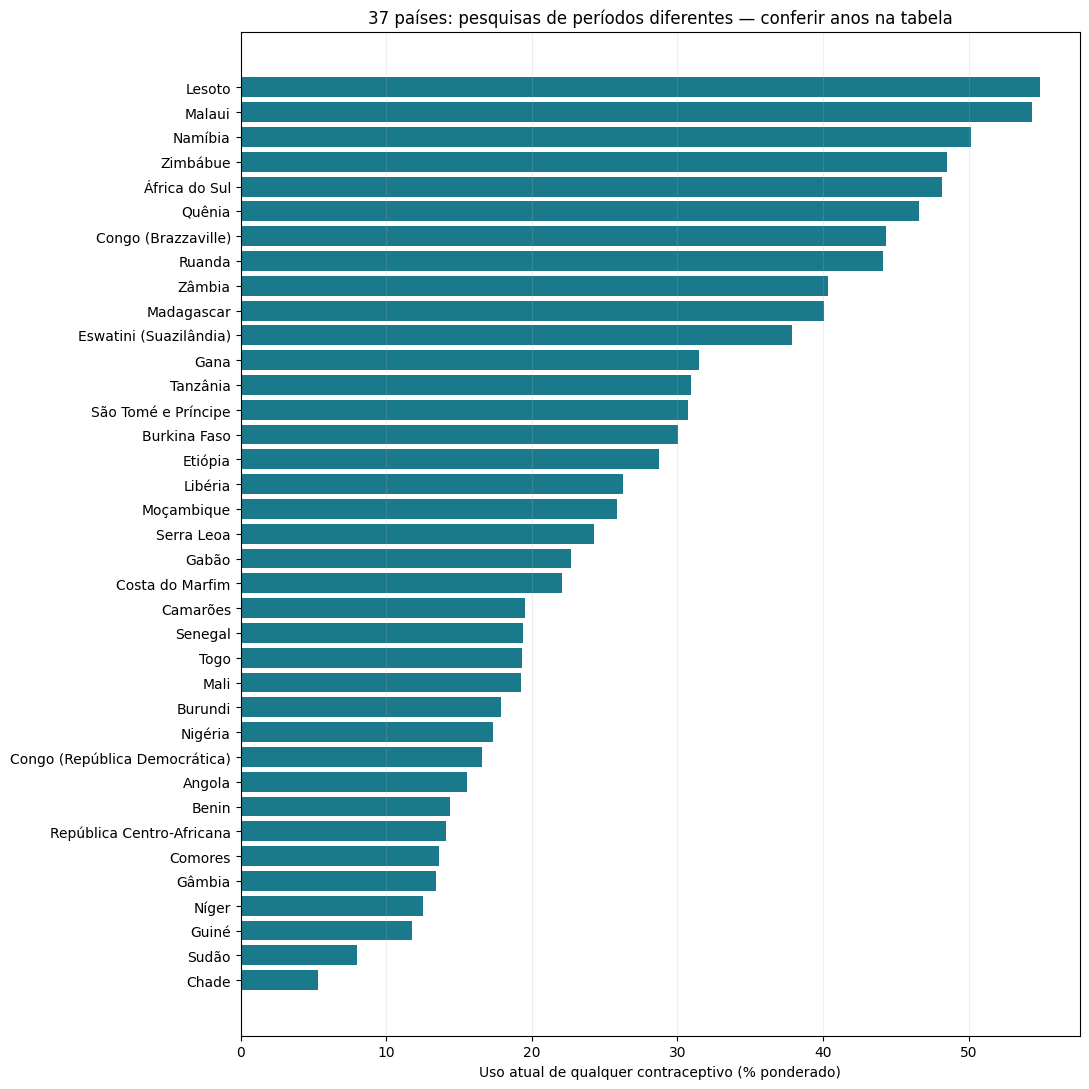

**Cobertura recuperada:** os 37 países têm respostas contraceptivas. A diferença entre países reúne contextos e anos distintos; ela sugere onde investigar, sem ordenar a qualidade das políticas públicas.

In [4]:
# Uma pesquisa temática por país; pesos calculados dentro dessa pesquisa.
panorama=consulta("""
SELECT p.codigo,p.nome,l.fase,MIN(e.ano) AS ano_min,MAX(e.ano) AS ano_max,
COUNT(*) AS entrevistas,SUM(e.usa_metodo IS NOT NULL AND e.peso>0) AS respostas_validas,
ROUND(100.0*SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso>0 THEN e.peso*e.usa_metodo END)/
NULLIF(SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso>0 THEN e.peso END),0),2) AS uso_percentual
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.coorte!='nucleo_exclusivo' GROUP BY p.codigo,p.nome,l.fase ORDER BY p.nome
""")
assert len(panorama)==37 and panorama.uso_percentual.notna().all()
fig,ax=plt.subplots(figsize=(11,11))
ordenado=panorama.sort_values('uso_percentual')
ax.barh(ordenado.nome,ordenado.uso_percentual,color='#1a7a8c')
ax.set_xlabel('Uso atual de qualquer contraceptivo (% ponderado)')
ax.set_title('37 países: pesquisas de períodos diferentes — conferir anos na tabela')
ax.grid(axis='x',alpha=.2); fig.tight_layout(); display(fig); plt.close(fig)
display(Markdown('**Cobertura recuperada:** os 37 países têm respostas contraceptivas. A diferença entre países reúne contextos e anos distintos; ela sugere onde investigar, sem ordenar a qualidade das políticas públicas.'))


# 4. Diagrama ER

O diagrama corresponde às relações efetivamente carregadas. O modelo tem dez tipos de entidade/relação; Levantamento, Domicílio, Mulher, Nascimento, Criança e Método atendem folgadamente ao requisito de identificador mais dois atributos. Mulher conhece Método é **M:N**, materializado por `Conhecimento_Metodo`; os dois lados possuem múltiplos vínculos.

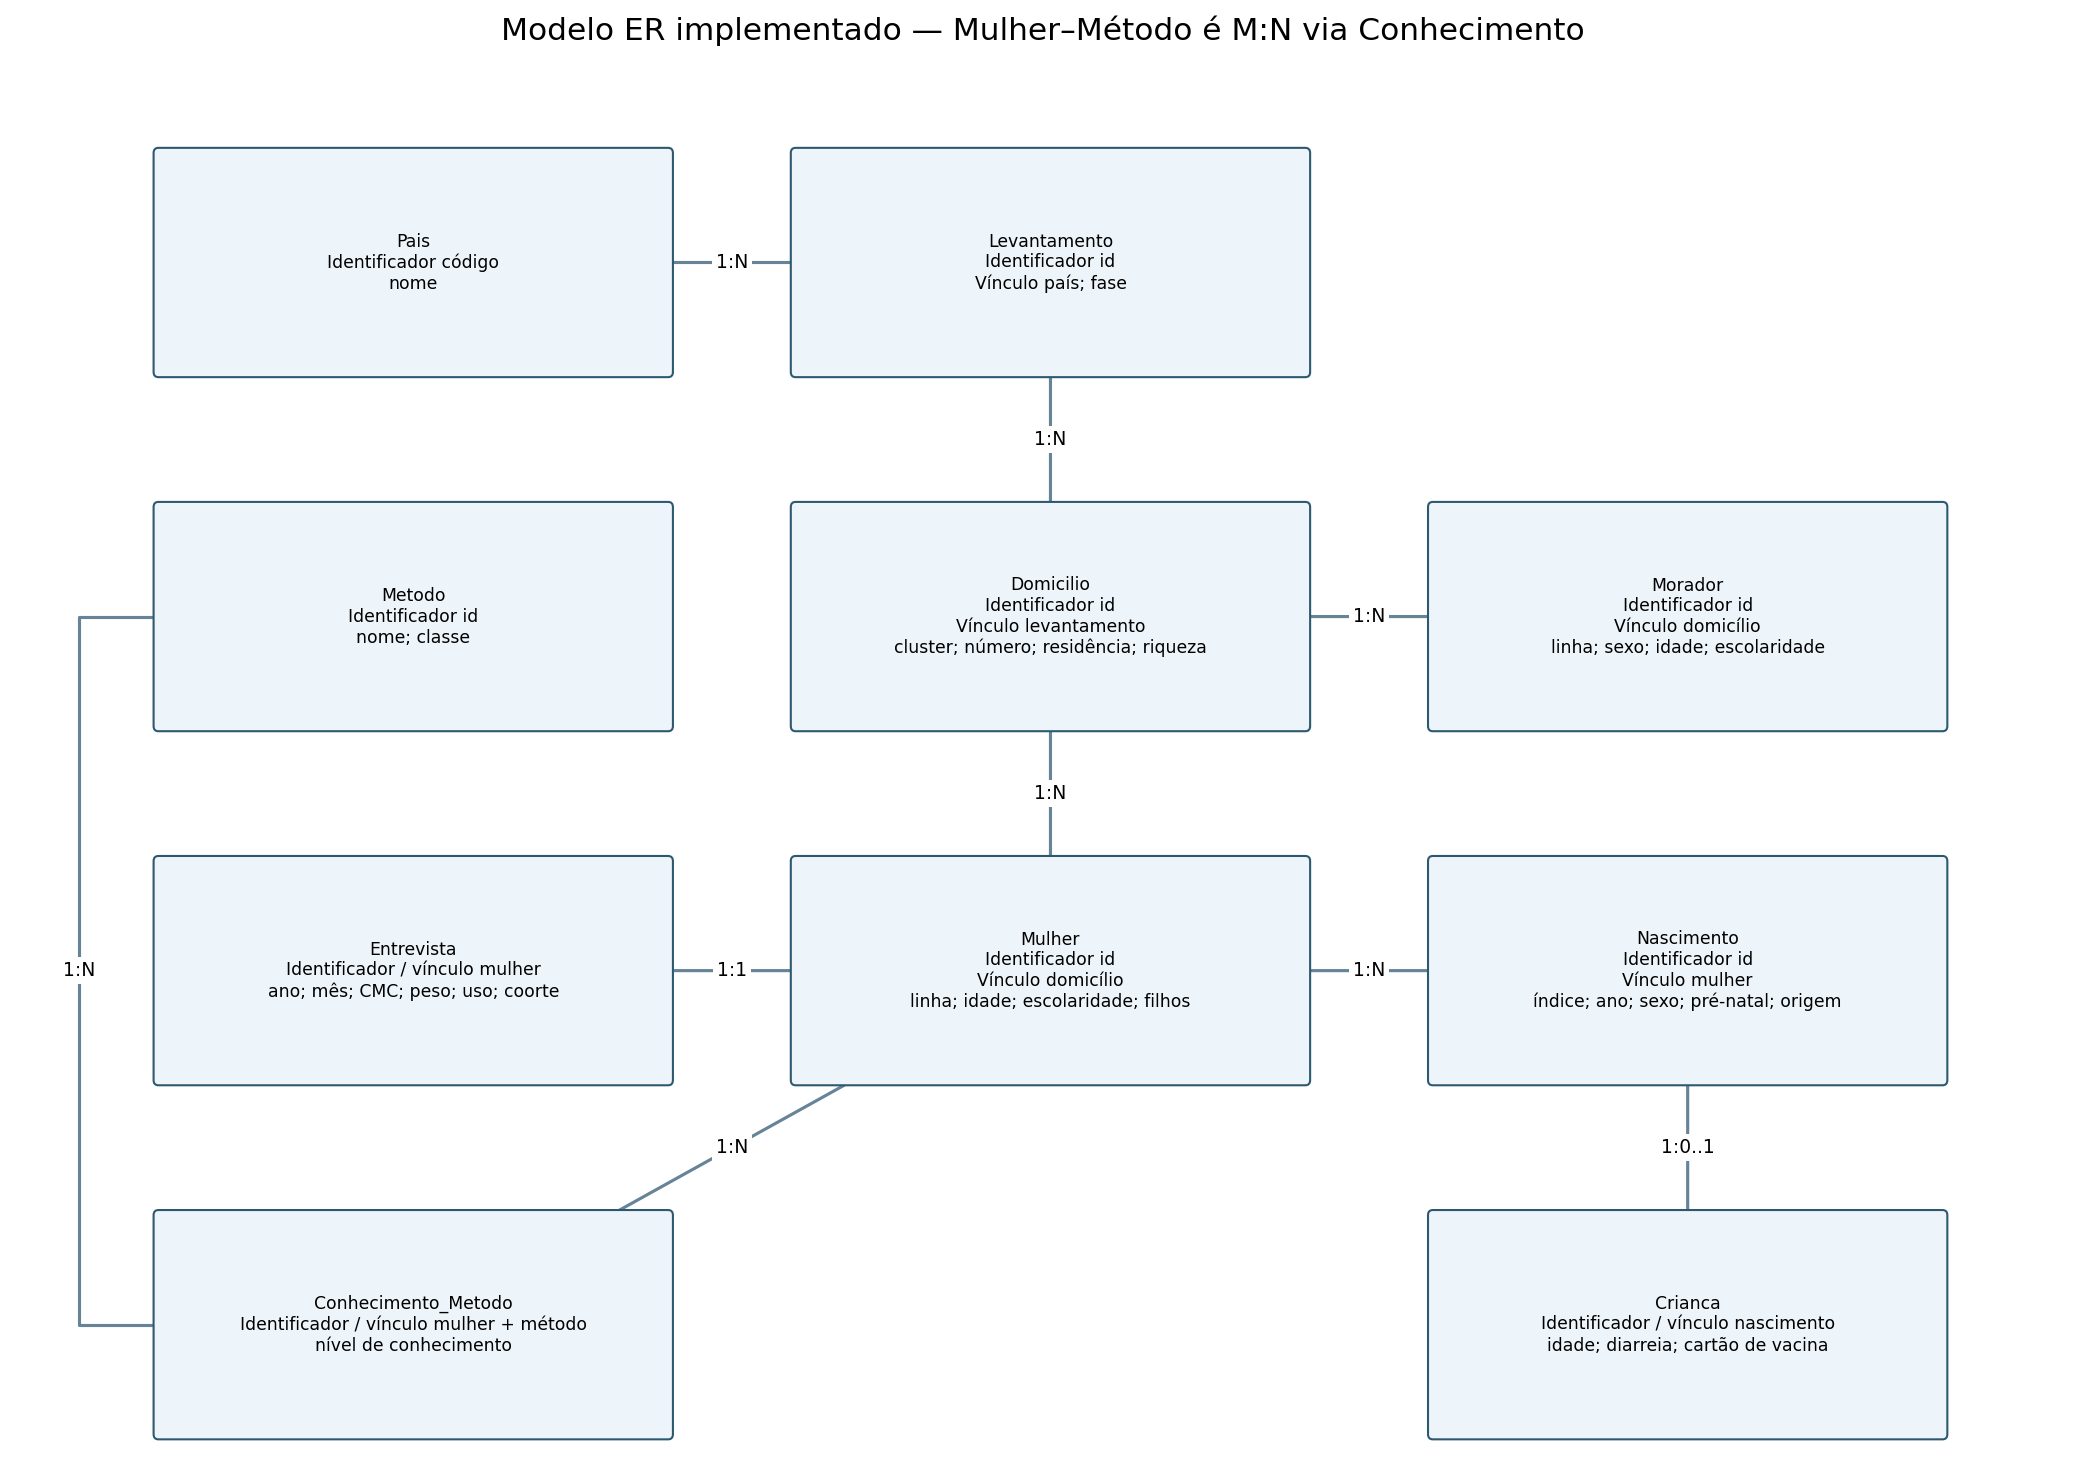

In [5]:
vinculos=consulta("""
SELECT (SELECT COUNT(*) FROM Conhecimento_Metodo WHERE nivel>0) AS vinculos_positivos,
       (SELECT COUNT(*) FROM (SELECT mulher_id FROM Conhecimento_Metodo WHERE nivel>0 GROUP BY mulher_id HAVING COUNT(*)>1)) AS mulheres_conhecem_varios,
       (SELECT COUNT(*) FROM (SELECT metodo_id FROM Conhecimento_Metodo WHERE nivel>0 GROUP BY metodo_id HAVING COUNT(*)>1)) AS metodos_conhecidos_por_varias
""")
assert vinculos.mulheres_conhecem_varios.iloc[0]>0 and vinculos.metodos_conhecidos_por_varias.iloc[0]==9

,vinculos_positivos,mulheres_conhecem_varios,metodos_conhecidos_por_varias
0,2851767,459441,9


# 5. Diagrama relacional

PK identifica a linha; FK exige que sua entidade referenciada exista. `Conhecimento_Metodo` tem PK composta; `Entrevista` usa a PK de Mulher e `Crianca` usa a PK de Nascimento. As chaves naturais também recebem `UNIQUE`. Campos desconhecidos permanecem NULL; os códigos brutos de saúde são preservados para evitar equiparar ausência a zero.

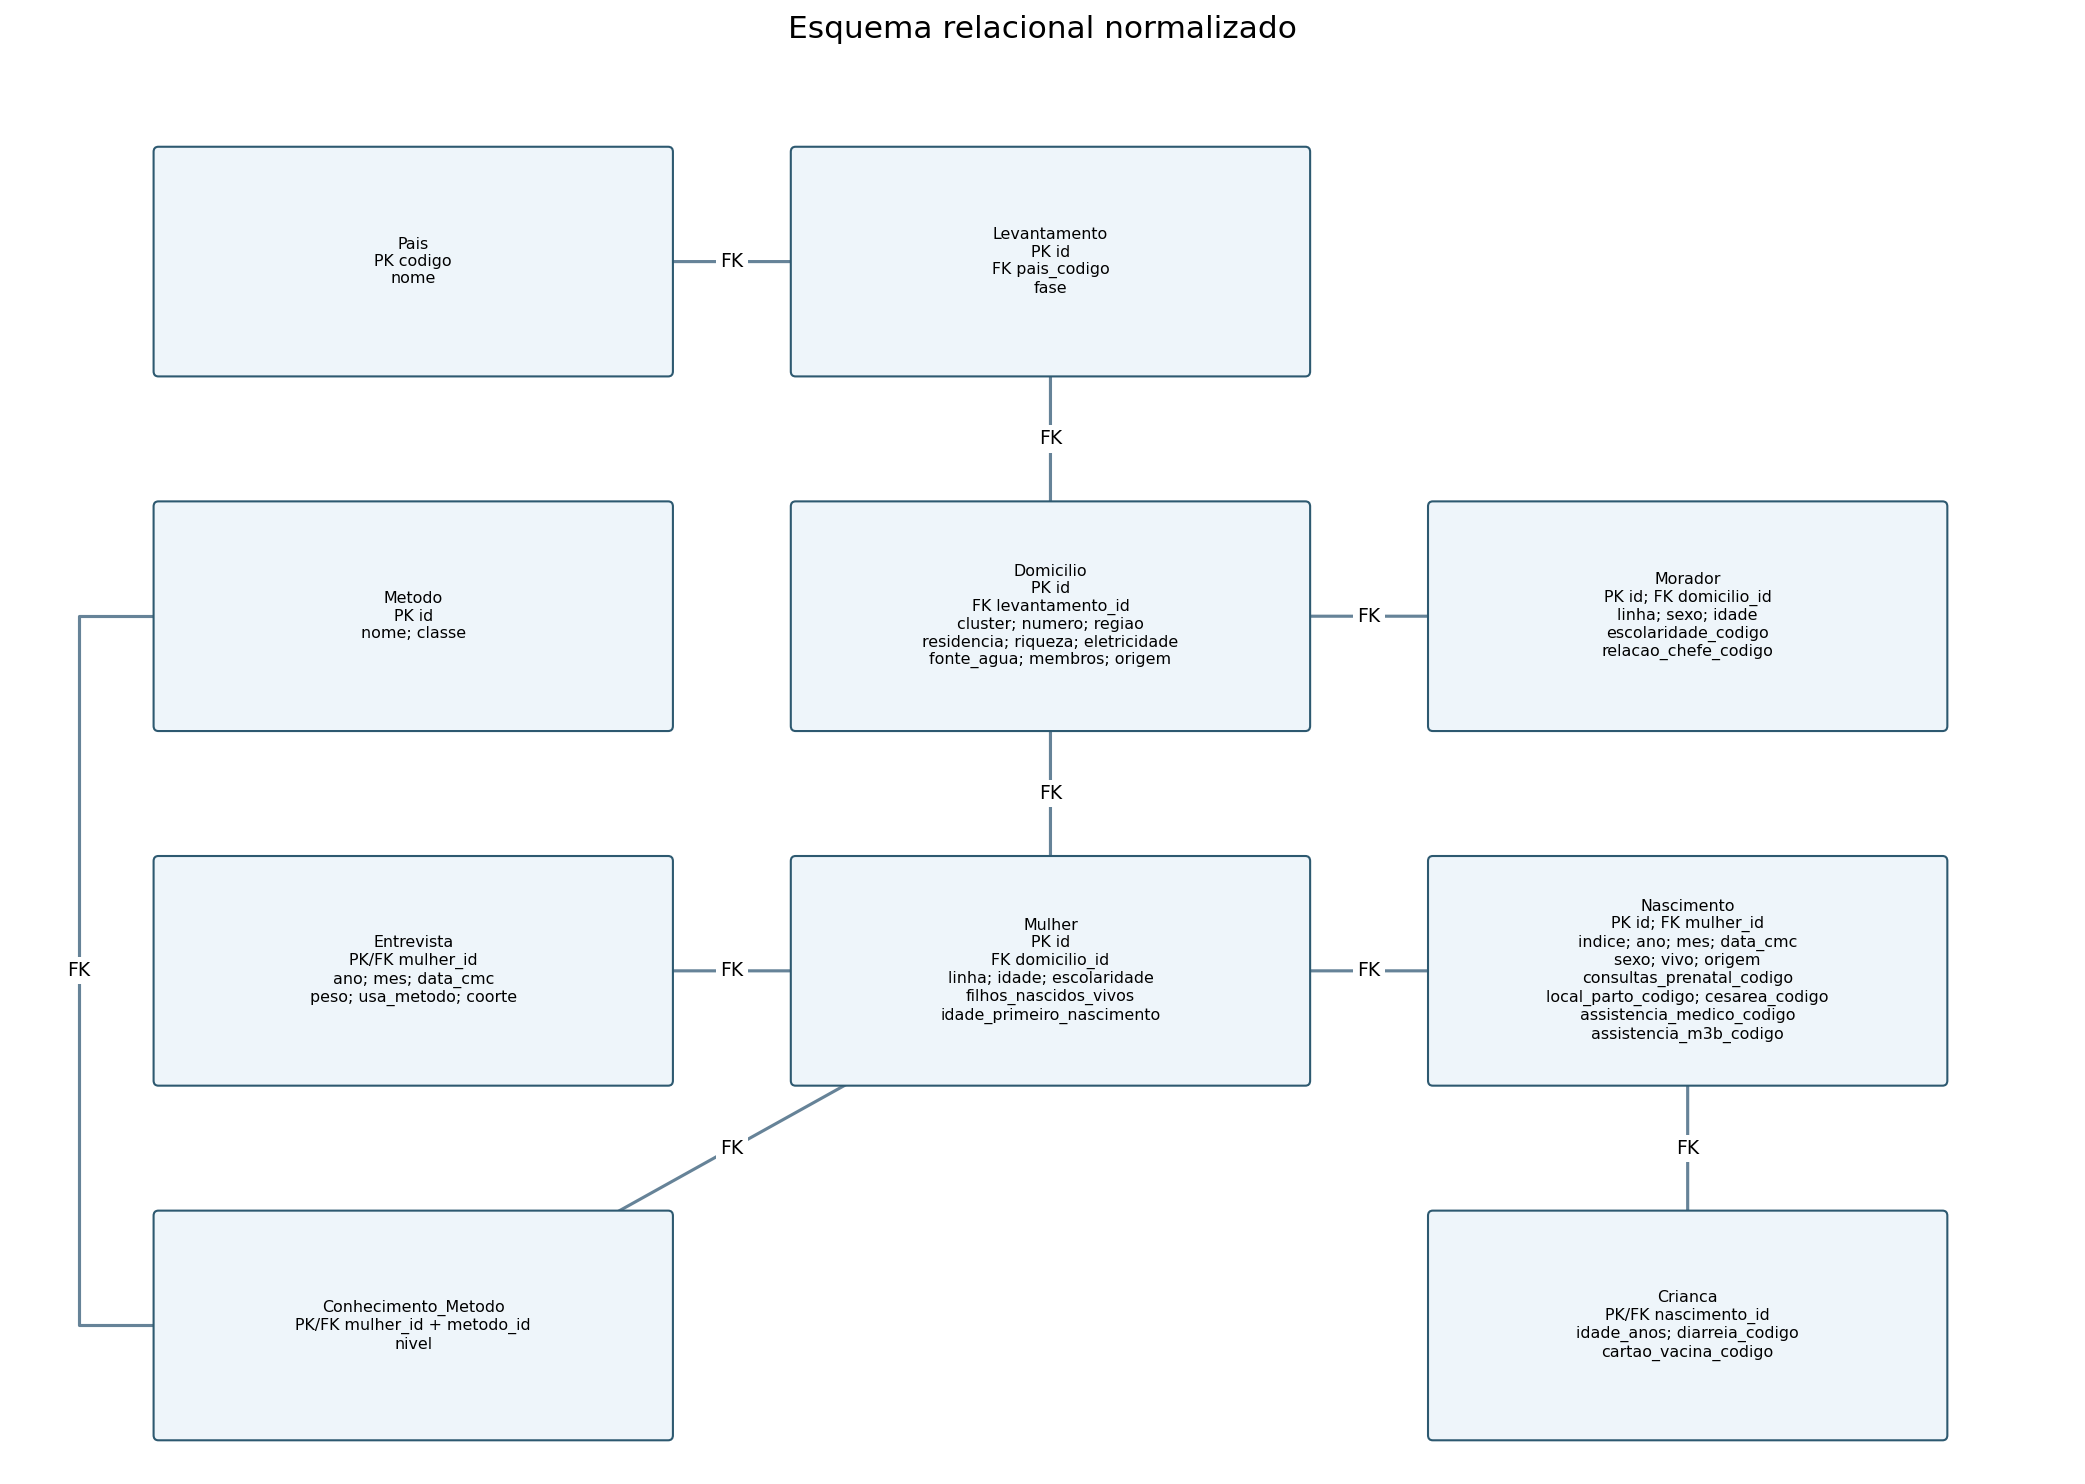

In [6]:
restricoes=consulta("""
SELECT name AS tabela, sql AS definicao_implementada
FROM sqlite_master WHERE type='table' ORDER BY name
""")

,tabela,definicao_implementada
0,Conhecimento_Metodo,CREATE TABLE Conhecimento_Metodo(\n m...
1,Crianca,CREATE TABLE Crianca(\n nascimento_id...
2,Domicilio,CREATE TABLE Domicilio(\n id TEXT PRI...
3,Entrevista,CREATE TABLE Entrevista(\n mulher_id ...
4,Levantamento,"CREATE TABLE Levantamento(id TEXT PRIMARY KEY,..."
5,Metodo,CREATE TABLE Metodo(\n id INTEGER PRI...
6,Morador,CREATE TABLE Morador(\n id TEXT PRIMA...
7,Mulher,CREATE TABLE Mulher(\n id TEXT PRIMAR...
8,Nascimento,CREATE TABLE Nascimento(\n id TEXT PR...
9,Pais,"CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nom..."


# 6. Consultas, resultados e análise

Todas as consultas percorrem o conjunto de países disponível. Nas consultas 1 e 2, a SQL recupera todos os registros elegíveis; a exibição mostra contagens e um exemplo de **cada país presente**, sem privilegiar o primeiro arquivo. As demais tabelas mostram comparações agregadas, não as primeiras dez linhas de Angola.

**Perguntas sociais:** diferenças rurais persistem quando riqueza e escolaridade são comparáveis? O conhecimento de métodos acompanha o uso? A cobertura do pré-natal apresenta gradientes de riqueza semelhantes entre países? A ausência de dados pode distorcer a ordem dos países?

As consultas 3, 5, 6 e 7 usam contagens ou proporções amostrais não ponderadas; 4, 8, 9 e 10 utilizam pesos. Quintis de riqueza são posições relativas dentro de cada país: o quintil mais pobre de dois países não implica a mesma renda ou privação absoluta. Escolaridade e riqueza também não controlam idade, estado conjugal, preferências reprodutivas ou acesso aos serviços.


**Cobertura dos cruzamentos:** o Sudão tem mulheres no inventário, mas residência e riqueza ausentes em IR e nenhum HR selecionado. Ele permanece na cobertura dos 37 países; não entra nas estratificações rural–urbano/riqueza. Outros países também podem faltar em indicadores específicos por ausência de resposta ou suporte comum. Exclusão analítica é informada, não convertida em zero.


**Coortes:** consultas 4, 8 e 9 selecionam uma pesquisa contraceptiva por país, usando o suplemento quando o núcleo não contém o módulo. Consultas 3, 6, 7 e 10 mantêm o núcleo. Consulta 5 separa levantamento; consultas 1 e 2 são listagens de observações elegíveis, sem interpretação como prevalência conjunta.


Resultados extensos ficam em tabelas expansíveis com todas as linhas e um inventário por país. Assim, países intermediários não desaparecem pela truncagem padrão do pandas.


## 6.1 Duas consultas com seleção e projeção

### 6.1.1 Consulta 1

Seleção e projeção: adolescentes de 15–19 anos sem escolaridade. A identificação técnica começa pelo código do país; somente Mulher é consultada.

In [7]:
sql_1 = """
SELECT substr(id,1,2) AS pais_codigo,id AS mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos FROM Mulher WHERE idade BETWEEN 15 AND 19 AND escolaridade=0 ORDER BY id
"""
r1 = consulta(sql_1, amostra=True)

,pais_codigo,registros_selecionados
0,AO,457
1,BF,1087
2,BJ,956
3,BU,284
4,CD,469
5,CF,520
6,CG,98
7,CI,870
8,CM,506
9,ET,304


,pais_codigo,mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos
0,AO,AO_81|100|13|4,18,NaN,0
457,BF,BF_81|100|273|7,17,NaN,0
1544,BJ,BJ_71|101|116|3,16,NaN,0
2500,BU,BU_71|101|1615|2,18,18.0,1
2784,CD,CD_81|100|122|3,15,NaN,0
3253,CF,CF_31|101|7|11,16,NaN,0
3773,CG,CG_61|103|1|4,19,NaN,0
3871,CI,CI_81|101|4|8,15,NaN,0
4741,CM,CM_71|105|446|2,17,16.0,1
5247,ET,ET_81|102|32|2,19,19.0,1


21,043 linhas consultadas; exibição de um exemplo por país presente.


In [8]:
display(Markdown(f"**Leitura:** a consulta 1 encontrou {len(r1):,} registros elegíveis em {r1.pais_codigo.nunique()} países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências."))

**Leitura:** a consulta 1 encontrou 21,043 registros elegíveis em 37 países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências.

### 6.1.2 Consulta 2

Seleção e projeção: domicílios rurais no quintil mais pobre, sem eletricidade. Ausência de HR não conta como ausência de eletricidade.

In [9]:
sql_2 = """
SELECT substr(id,1,2) AS pais_codigo,id AS domicilio_id,fonte_agua,membros FROM Domicilio WHERE residencia=2 AND riqueza=1 AND eletricidade=0 ORDER BY id
"""
r2 = consulta(sql_2, amostra=True)

,pais_codigo,registros_selecionados
0,AO,4159
1,BF,2195
2,BJ,1840
3,BU,3305
4,CD,7091
5,CG,4987
6,CI,2554
7,CM,867
8,ET,1960
9,GA,2394


,pais_codigo,domicilio_id,fonte_agua,membros
0,AO,AO_81|101|17,43.0,2
4159,BF,BF_81|11|20,21.0,5
6354,BJ,BJ_71|100|130,14.0,3
8194,BU,BU_71|101|1476,32.0,3
11499,CD,CD_81|100|102,42.0,4
18590,CG,CG_61|101|11,13.0,1
23577,CI,CI_81|100|10,21.0,7
26131,CM,CM_82|136|10,42.0,4
26998,ET,ET_81|100|10,42.0,5
28958,GA,GA_71|103|1,43.0,2


75,029 linhas consultadas; exibição de um exemplo por país presente.


In [10]:
display(Markdown(f"**Leitura:** a consulta 2 encontrou {len(r2):,} registros elegíveis em {r2.pais_codigo.nunique()} países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências."))

**Leitura:** a consulta 2 encontrou 75,029 registros elegíveis em 35 países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências.

## 6.2 Três consultas com junção de duas relações

### 6.2.1 Consulta 3

Junção de duas relações (Mulher–Domicilio): composição demográfica rural e urbana em cada país. Média de filhos é descritiva e não uma taxa de fecundidade.

In [11]:
sql_3 = """
SELECT substr(d.id,1,2) AS pais_codigo,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS mulheres,ROUND(AVG(m.idade),2) AS idade_media,
ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Mulher m JOIN Domicilio d ON d.id=m.domicilio_id WHERE d.origem!='IR_completo' AND d.residencia IN(1,2)
GROUP BY substr(d.id,1,2),d.residencia ORDER BY pais_codigo,d.residencia
"""
r3 = consulta(sql_3, amostra=False)

,pais_codigo,residencia,mulheres,idade_media,filhos_medios,percentual_sem_escola
0,AO,Urbano,9066,26.87,2.19,10.07
1,AO,Rural,5651,27.99,3.17,40.93
2,BF,Urbano,6227,27.98,2.01,36.29
3,BF,Rural,11432,29.23,3.17,69.93
4,BJ,Urbano,7045,28.59,2.51,42.60
...,...,...,...,...,...,...
67,ZA,Rural,3709,29.76,1.81,2.80
68,ZM,Urbano,6131,28.33,2.05,3.00
69,ZM,Rural,7820,28.33,2.94,9.91
70,ZW,Urbano,4521,28.63,1.67,0.29


In [12]:
comparacao=r3.pivot(index='pais_codigo',columns='residencia',values='percentual_sem_escola').dropna()
maior=(comparacao.Rural>comparacao.Urbano).sum()
display(Markdown(f"**Leitura:** a proporção não ponderada de mulheres sem escola é maior no meio rural em {maior} de {len(comparacao)} países com ambas as áreas. Essa composição deve ser considerada antes de atribuir as diferenças contraceptivas apenas ao território."))

**Leitura:** a proporção não ponderada de mulheres sem escola é maior no meio rural em 35 de 36 países com ambas as áreas. Essa composição deve ser considerada antes de atribuir as diferenças contraceptivas apenas ao território.

### 6.2.2 Consulta 4

Junção de duas relações (Entrevista–Mulher): uso de algum contraceptivo por nível de escolaridade em cada país. O denominador usa resposta válida e peso positivo.

A seleção pela coorte evita reunir entrevistas de duas pesquisas do mesmo país.


In [13]:
sql_4 = """
SELECT substr(m.id,1,2) AS pais_codigo,m.escolaridade,COUNT(*) AS respostas_validas,
ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
WHERE e.coorte!='nucleo_exclusivo' AND e.usa_metodo IS NOT NULL AND e.peso>0 AND m.escolaridade IS NOT NULL
GROUP BY substr(m.id,1,2),m.escolaridade ORDER BY pais_codigo,m.escolaridade
"""
r4 = consulta(sql_4, amostra=False)

pais_codigo,escolaridade,respostas_validas,percentual_uso_ponderado
AO,0,3226,5.31
AO,1,4149,10.82
AO,2,6747,20.30
AO,3,595,28.28
BF,0,10254,29.04
BF,1,2515,31.30
BF,2,4548,30.46
BF,3,342,43.92
BJ,0,8762,12.42
BJ,1,3116,14.57


,pais_codigo,linhas_no_resultado
0,AO,4
1,BF,4
2,BJ,4
3,BU,4
4,CD,4
5,CF,4
6,CG,4
7,CI,4
8,CM,4
9,ET,4


In [14]:
extremos=r4[r4.escolaridade.isin([0,3])].pivot(index='pais_codigo',columns='escolaridade',values='percentual_uso_ponderado').dropna()
display(Markdown(f"**Leitura:** entre os {len(extremos)} países com respostas nos dois extremos de escolaridade, {int((extremos[3]>extremos[0]).sum())} apresentam maior uso ponderado no nível superior do que entre mulheres sem escola. Idade, estado conjugal, preferências reprodutivas e acesso podem explicar parte da associação."))

**Leitura:** entre os 37 países com respostas nos dois extremos de escolaridade, 31 apresentam maior uso ponderado no nível superior do que entre mulheres sem escola. Idade, estado conjugal, preferências reprodutivas e acesso podem explicar parte da associação.

### 6.2.3 Consulta 5

Junção de duas relações (Conhecimento_Metodo–Metodo): conhecimento dos nove métodos por país. Cada denominador contém quem respondeu àquele método; percentuais não ponderados, pois esta categoria usa somente duas relações.

Os resultados são separados por levantamento para não misturar ondas de coleta.


In [15]:
sql_5 = """
SELECT substr(k.mulher_id,1,2) AS pais_codigo,substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,t.nome,t.classe,COUNT(*) AS respostas_validas,
SUM(k.nivel>0) AS conhecem,ROUND(100.0*SUM(k.nivel>0)/COUNT(*),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k JOIN Metodo t ON t.id=k.metodo_id
GROUP BY substr(k.mulher_id,1,2),levantamento,t.id,t.nome,t.classe ORDER BY pais_codigo,t.id
"""
r5 = consulta(sql_5, amostra=False)

pais_codigo,levantamento,nome,classe,respostas_validas,conhecem,percentual_conhecimento
AO,AO_81,Pílula,Moderno,14717,9755,66.28
AO,AO_81,DIU,Moderno,14717,5486,37.28
AO,AO_81,Injetáveis,Moderno,14717,9511,64.63
AO,AO_81,Preservativo masculino,Moderno,14717,11692,79.45
AO,AO_81,Esterilização feminina,Moderno,14717,3215,21.85
AO,AO_81,Esterilização masculina,Moderno,14717,2307,15.68
AO,AO_81,Abstinência periódica,Tradicional,14717,4959,33.70
AO,AO_81,Coito interrompido,Tradicional,14717,5447,37.01
BF,BF_81,Pílula,Moderno,17659,15830,89.64
BF,BF_81,DIU,Moderno,17659,10978,62.17


,pais_codigo,linhas_no_resultado
0,AO,8
1,BF,9
2,BJ,9
3,BU,9
4,CD,9
5,CF,9
6,CG,9
7,CI,9
8,CM,9
9,ET,9


In [16]:
display(Markdown(f"**Leitura:** o M:N contém respostas válidas em {r5.pais_codigo.nunique()} países. As categorias de conhecimento variam na cobertura; não comparar a soma de todos os métodos como se fosse número de mulheres nem presumir que conhecimento resulta em uso."))

**Leitura:** o M:N contém respostas válidas em 37 países. As categorias de conhecimento variam na cobertura; não comparar a soma de todos os métodos como se fosse número de mulheres nem presumir que conhecimento resulta em uso.

## 6.3 Três consultas com junção de três ou mais relações

### 6.3.1 Consulta 6

Junção de cinco relações: pobreza material e escolaridade por país e residência, para distinguir composição socioeconômica de diferenças de saúde.

In [17]:
sql_6 = """
SELECT p.codigo,p.nome,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS mulheres,ROUND(100.0*SUM(d.riqueza=1)/NULLIF(SUM(d.riqueza IS NOT NULL),0),2) AS percentual_quintil_1,
ROUND(100.0*SUM(d.eletricidade=0)/NULLIF(SUM(d.eletricidade IS NOT NULL),0),2) AS percentual_sem_eletricidade,
ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo WHERE e.coorte!='contracepcao' AND d.residencia IN(1,2) GROUP BY p.codigo,p.nome,d.residencia ORDER BY p.nome,d.residencia
"""
r6 = consulta(sql_6, amostra=False)

,codigo,nome,residencia,mulheres,percentual_quintil_1,percentual_sem_eletricidade,percentual_sem_escola
0,AO,Angola,Urbano,9066,1.18,19.17,10.07
1,AO,Angola,Rural,5651,52.45,87.65,40.93
2,BJ,Benin,Urbano,7045,13.03,42.19,42.60
3,BJ,Benin,Rural,8883,21.82,77.43,64.85
4,BF,Burkina Faso,Urbano,6227,1.08,45.85,36.29
...,...,...,...,...,...,...,...
67,ZW,Zimbábue,Rural,5434,27.59,90.69,1.71
68,ZM,Zâmbia,Urbano,6131,0.16,31.27,3.00
69,ZM,Zâmbia,Rural,7820,36.00,94.50,9.91
70,ZA,África do Sul,Urbano,4805,9.76,6.35,1.79


In [18]:
material=r6.pivot(index='codigo',columns='residencia',values='percentual_sem_eletricidade').dropna()
display(Markdown(f"**Leitura:** a falta de eletricidade é mais frequente no meio rural em {int((material.Rural>material.Urbano).sum())} de {len(material)} países com informação nas duas áreas. O Sudão não possui HR neste recorte e não entra nessa comparação habitacional; seu dado ausente não é eletricidade presente."))

**Leitura:** a falta de eletricidade é mais frequente no meio rural em 36 de 36 países com informação nas duas áreas. O Sudão não possui HR neste recorte e não entra nessa comparação habitacional; seu dado ausente não é eletricidade presente.

### 6.3.2 Consulta 7

Junção de seis relações: disponibilidade da informação de pré-natal em nascimentos recentes. A análise usa somente o nascimento mais recente (índice 1), ocorrido nos 60 meses anteriores à entrevista, e distingue códigos ausentes/especiais.

In [19]:
sql_7 = """
SELECT p.codigo,p.nome,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS nascimentos_recentes,SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END) AS respostas_validas,
ROUND(100.0*SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END)/COUNT(*),2) AS cobertura_resposta_percentual
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo JOIN Nascimento n ON n.mulher_id=m.id
WHERE n.indice=1 AND e.data_cmc-n.data_cmc BETWEEN 0 AND 59 AND d.residencia IN(1,2)
GROUP BY p.codigo,p.nome,d.residencia ORDER BY p.nome,d.residencia
"""
r7 = consulta(sql_7, amostra=False)

,codigo,nome,residencia,nascimentos_recentes,respostas_validas,cobertura_resposta_percentual
0,AO,Angola,Urbano,4208,2992,71.10
1,AO,Angola,Rural,3617,2865,79.21
2,BJ,Benin,Urbano,3628,3513,96.83
3,BJ,Benin,Rural,5349,5237,97.91
4,BF,Burkina Faso,Urbano,2777,1859,66.94
...,...,...,...,...,...,...
67,ZW,Zimbábue,Rural,2927,2921,99.80
68,ZM,Zâmbia,Urbano,2456,1686,68.65
69,ZM,Zâmbia,Rural,4448,3265,73.40
70,ZA,África do Sul,Urbano,1596,1539,96.43


In [20]:
display(Markdown(f"**Leitura:** há nascimentos recentes em {r7.codigo.nunique()} países. A cobertura de respostas válidas de pré-natal varia de {r7.cobertura_resposta_percentual.min():.1f}% a {r7.cobertura_resposta_percentual.max():.1f}% entre os grupos país–residência. Um percentual de atendimento aparentemente alto pode descrever apenas a parte com informação registrada."))

**Leitura:** há nascimentos recentes em 36 países. A cobertura de respostas válidas de pré-natal varia de 0.0% a 100.0% entre os grupos país–residência. Um percentual de atendimento aparentemente alto pode descrever apenas a parte com informação registrada.

### 6.3.3 Consulta 8

Junção de cinco relações com o M:N e catálogo: conhecimento de ao menos um dos sete métodos modernos do recorte e uso atual de qualquer método. Usamos uma linha por mulher para impedir que quem conhece vários métodos seja contado várias vezes. A diferença entre indicadores não identifica individualmente demanda não atendida.

Conhecimento positivo exige ao menos uma resposta positiva; ausência de conhecimento exige respostas válidas para os sete métodos modernos. Respostas parciais sem nenhum positivo permanecem desconhecidas e são excluídas deste indicador, evitando um falso “não conhece”.


In [21]:
sql_8 = """
WITH conhecimento AS (
SELECT k.mulher_id,CASE WHEN MAX(k.nivel>0)=1 THEN 1 WHEN COUNT(*)=7 THEN 0 END AS conhece_moderno
FROM Conhecimento_Metodo k JOIN Metodo t ON t.id=k.metodo_id WHERE t.classe='Moderno' GROUP BY k.mulher_id)
SELECT p.codigo,p.nome,COUNT(*) AS mulheres_respostas_validas,
ROUND(100.0*SUM(e.peso*k.conhece_moderno)/SUM(e.peso),2) AS percentual_conhece_moderno,
ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_qualquer
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo JOIN conhecimento k ON k.mulher_id=m.id
WHERE e.coorte!='nucleo_exclusivo' AND e.usa_metodo IS NOT NULL AND e.peso>0 AND k.conhece_moderno IS NOT NULL
GROUP BY p.codigo,p.nome ORDER BY p.nome
"""
r8 = consulta(sql_8, amostra=False)

,codigo,nome,mulheres_respostas_validas,percentual_conhece_moderno,percentual_uso_qualquer
0,AO,Angola,11999,100.00,18.26
1,BJ,Benin,15928,100.00,14.41
2,BF,Burkina Faso,17659,100.00,30.06
3,BU,Burundi,17269,100.00,17.89
4,CM,Camarões,13527,100.00,19.52
5,TD,Chade,17719,100.00,5.35
6,KM,Comores,5329,100.00,13.66
7,CG,Congo (Brazzaville),10819,100.00,44.34
8,CD,Congo (República Democrática),27583,100.00,16.55
9,CI,Costa do Marfim,14877,100.00,22.05


In [22]:
r8['diferenca_pp']=r8.percentual_conhece_moderno-r8.percentual_uso_qualquer
display(r8[['nome','mulheres_respostas_validas','diferenca_pp']])
display(Markdown(f"**Leitura:** conhecimento moderno e uso de qualquer método diferem em magnitude entre {len(r8)} países. O descompasso sugere investigar barreiras e preferências, mas os indicadores têm conceitos diferentes e não medem necessidade não atendida."))

,nome,mulheres_respostas_validas,diferenca_pp
0,Angola,11999,81.74
1,Benin,15928,85.59
2,Burkina Faso,17659,69.94
3,Burundi,17269,82.11
4,Camarões,13527,80.48
5,Chade,17719,94.65
6,Comores,5329,86.34
7,Congo (Brazzaville),10819,55.66
8,Congo (República Democrática),27583,83.45
9,Costa do Marfim,14877,77.95


**Leitura:** conhecimento moderno e uso de qualquer método diferem em magnitude entre 37 países. O descompasso sugere investigar barreiras e preferências, mas os indicadores têm conceitos diferentes e não medem necessidade não atendida.

## 6.4 Duas consultas com agregação sobre junção

### 6.4.1 Consulta 9

Agregação sobre cinco relações: uso contraceptivo por país, residência, quintil de riqueza e escolaridade. Essa tabela fornece os estratos para separar composição socioeconômica da diferença rural–urbana.

In [23]:
sql_9 = """
SELECT p.codigo,p.nome,d.residencia,d.riqueza,m.escolaridade,COUNT(*) AS n,
SUM(e.peso) AS peso_total,SUM(e.peso*e.usa_metodo) AS peso_uso
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo WHERE e.coorte!='nucleo_exclusivo' AND e.usa_metodo IS NOT NULL AND e.peso>0 AND d.residencia IN(1,2)
AND d.riqueza BETWEEN 1 AND 5 AND m.escolaridade BETWEEN 0 AND 3
GROUP BY p.codigo,p.nome,d.residencia,d.riqueza,m.escolaridade ORDER BY p.nome,d.residencia,d.riqueza,m.escolaridade
"""
r9 = consulta(sql_9, amostra=False)

codigo,nome,residencia,riqueza,escolaridade,n,peso_total,peso_uso
AO,Angola,1,1,0,44,32.537380,0.379562
AO,Angola,1,1,1,37,34.691687,1.096992
AO,Angola,1,1,2,26,20.120082,2.879600
AO,Angola,1,2,0,284,210.090319,7.097133
AO,Angola,1,2,1,365,305.121579,15.571363
AO,Angola,1,2,2,281,233.272810,39.209519
AO,Angola,1,3,0,354,266.940714,17.497694
AO,Angola,1,3,1,813,774.803185,113.595157
AO,Angola,1,3,2,1523,1373.433466,252.920204
AO,Angola,1,3,3,23,13.033430,2.390045


,codigo,linhas_no_resultado
0,AO,36
1,BF,36
2,BJ,35
3,BU,34
4,CD,40
5,CG,36
6,CI,39
7,CM,39
8,ET,39
9,GA,40


### 6.4.2 Consulta 10

Agregação sobre seis relações: pré-natal de quatro ou mais consultas por país, residência e riqueza. O denominador clínico considera somente o nascimento mais recente nos últimos 60 meses com resposta válida; a cobertura aparece separadamente.

In [24]:
sql_10 = """
SELECT p.codigo,p.nome,d.residencia,d.riqueza,COUNT(*) AS nascimentos_recentes,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END) AS n_validos,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4 AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo JOIN Nascimento n ON n.mulher_id=m.id
WHERE n.indice=1 AND e.data_cmc-n.data_cmc BETWEEN 0 AND 59 AND e.peso>0
AND d.residencia IN(1,2) AND d.riqueza BETWEEN 1 AND 5
GROUP BY p.codigo,p.nome,d.residencia,d.riqueza ORDER BY p.nome,d.residencia,d.riqueza
"""
r10 = consulta(sql_10, amostra=False)

codigo,nome,residencia,riqueza,nascimentos_recentes,n_validos,peso_valido,peso_quatro_mais
AO,Angola,1,1,66,50,38.705283,14.212405
AO,Angola,1,2,558,425,338.977883,144.427086
AO,Angola,1,3,1537,1127,974.057613,618.625296
AO,Angola,1,4,1174,795,870.177007,702.901841
AO,Angola,1,5,873,595,710.826592,649.617429
AO,Angola,2,1,1946,1548,1229.179719,312.428171
AO,Angola,2,2,1245,993,967.351867,360.262453
AO,Angola,2,3,336,260,201.882627,116.874049
AO,Angola,2,4,60,46,36.156285,25.425303
AO,Angola,2,5,30,18,12.173921,11.714798


,codigo,linhas_no_resultado
0,AO,10
1,BF,10
2,BJ,10
3,BU,10
4,CD,10
5,CG,9
6,CI,10
7,CM,10
8,ET,10
9,GA,10


## 6.5 Cruzamentos entre países e visualizações

**Contracepção: diferença bruta e padronizada.** Para cada país da consulta 9, formamos estratos riqueza × escolaridade com pelo menos 30 respostas válidas em **cada** área. Usamos somente o suporte comum rural/urbano. Calculamos taxas ponderadas dentro dos estratos e aplicamos, às duas áreas, a mesma distribuição conjunta de riqueza e escolaridade (pesos combinados do próprio país). A diferença padronizada não é efeito causal.

Comparamos a diferença bruta **nessa mesma subamostra**, antes da padronização, com a diferença padronizada. Assim, uma eventual inversão não decorre apenas de excluir estratos de uma das versões. A participação do suporte comum em cada área é mostrada; países sem suporte suficiente permanecem explicitamente ausentes.

,codigo,pais,estratos,bruta_pp,padronizada_pp,suporte_urbano_pct,suporte_rural_pct,inversao
27,ST,São Tomé e Príncipe,10,-8.59,-9.73,92.96,93.38,False
17,MD,Madagascar,15,-2.77,-6.96,98.91,95.87,False
33,ZM,Zâmbia,11,-7.62,-5.58,93.60,63.76,False
13,KE,Quênia,17,1.86,-4.93,99.16,98.49,True
15,LB,Libéria,13,1.55,-4.45,82.43,98.37,True
10,GH,Gana,16,-0.37,-4.05,97.29,99.05,False
8,ET,Etiópia,11,2.00,-3.90,94.09,73.05,True
0,AO,Angola,10,11.47,-3.43,79.43,94.56,True
24,RW,Ruanda,15,-8.57,-2.89,98.84,99.20,False
6,CI,Costa do Marfim,14,5.86,-2.65,84.91,98.98,True


Países sem suporte comum suficiente: CF, SD


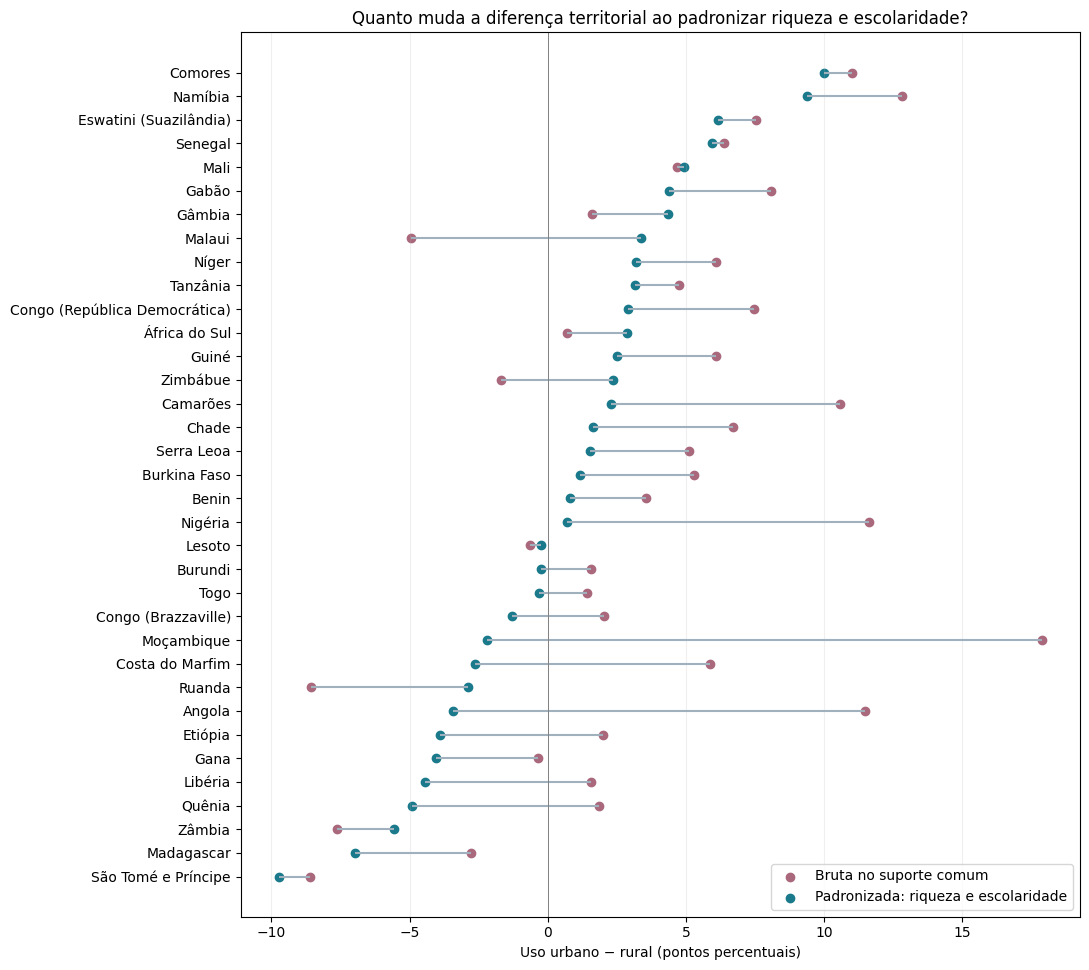

**Achado:** 35 países têm suporte comum. Em 20, o uso urbano permanece maior após padronizar riqueza e escolaridade. Houve 11 inversões de sinal entre a comparação bruta e padronizada na mesma subamostra; países: Quênia, Libéria, Etiópia, Angola, Costa do Marfim, Moçambique, Congo (Brazzaville), Togo, Burundi, Zimbábue, Malaui. As maiores mudanças em magnitude aparecem em Moçambique, Angola, Nigéria. Isso mostra por que uma média conjunta pode esconder padrões diferentes entre países.

In [25]:
ajustes=[]
for (codigo,nome),g in r9.groupby(['codigo','nome']):
    n=g.pivot(index=['riqueza','escolaridade'],columns='residencia',values='n')
    suporte=n.index[(n.get(1,0)>=30)&(n.get(2,0)>=30)]
    if len(suporte)==0: continue
    sub=g.set_index(['riqueza','escolaridade']).loc[suporte].reset_index()
    wt=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_total')
    uso=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_uso')
    padrao=(wt[1]+wt[2]); padrao=padrao/padrao.sum()
    bruto=100*(uso[1].sum()/wt[1].sum()-uso[2].sum()/wt[2].sum())
    ajustado=100*((uso[1]/wt[1]-uso[2]/wt[2])*padrao).sum()
    totais=g.groupby('residencia').peso_total.sum()
    ajustes.append([codigo,nome,len(suporte),bruto,ajustado,
                    100*wt[1].sum()/totais[1],100*wt[2].sum()/totais[2]])
ajustes=pd.DataFrame(ajustes,columns=['codigo','pais','estratos','bruta_pp','padronizada_pp','suporte_urbano_pct','suporte_rural_pct'])
ajustes['inversao']=ajustes.bruta_pp*ajustes.padronizada_pp<0
ajustes=ajustes.sort_values('padronizada_pp')
display(ajustes.round(2))
ausentes=sorted(set(cobertura.codigo)-set(ajustes.codigo))
print('Países sem suporte comum suficiente:', ', '.join(ausentes) or 'nenhum')
fig,ax=plt.subplots(figsize=(11,max(7,len(ajustes)*.28)))
y=np.arange(len(ajustes))
ax.hlines(y,ajustes.bruta_pp,ajustes.padronizada_pp,color='#a0b0bc')
ax.scatter(ajustes.bruta_pp,y,label='Bruta no suporte comum',color='#aa687c')
ax.scatter(ajustes.padronizada_pp,y,label='Padronizada: riqueza e escolaridade',color='#1a7a8c')
ax.set_yticks(y,ajustes.pais); ax.axvline(0,color='gray',lw=.7)
ax.set_xlabel('Uso urbano − rural (pontos percentuais)'); ax.set_title('Quanto muda a diferença territorial ao padronizar riqueza e escolaridade?')
ax.legend(loc='best'); ax.grid(axis='x',alpha=.2); fig.tight_layout(); display(fig); plt.close(fig)
inversoes=ajustes[ajustes.inversao]
maiores=ajustes.assign(mudanca=(ajustes.bruta_pp-ajustes.padronizada_pp).abs()).nlargest(3,'mudanca')
display(Markdown(f"**Achado:** {len(ajustes)} países têm suporte comum. Em {int((ajustes.padronizada_pp>0).sum())}, o uso urbano permanece maior após padronizar riqueza e escolaridade. Houve {len(inversoes)} inversões de sinal entre a comparação bruta e padronizada na mesma subamostra; " +
                ("países: "+', '.join(inversoes.pais)+'. ' if len(inversoes) else "não se demonstrou inversão de sinal. ")+ 
                "As maiores mudanças em magnitude aparecem em "+', '.join(maiores.pais)+". Isso mostra por que uma média conjunta pode esconder padrões diferentes entre países."))

In [26]:
# Sensibilidade: verificar inversões com mais respostas por estrato.
sensibilidade=[]
for minimo in [30,50,100]:
    for (codigo,nome),g in r9.groupby(['codigo','nome']):
        numeros=g.pivot(index=['riqueza','escolaridade'],columns='residencia',values='n')
        suporte=numeros.index[(numeros.get(1,0)>=minimo)&(numeros.get(2,0)>=minimo)]
        if len(suporte)==0: continue
        sub=g.set_index(['riqueza','escolaridade']).loc[suporte].reset_index()
        wt=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_total')
        uso=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_uso')
        padrao=(wt[1]+wt[2]); padrao=padrao/padrao.sum()
        bruta=100*(uso[1].sum()/wt[1].sum()-uso[2].sum()/wt[2].sum())
        ajustada=100*((uso[1]/wt[1]-uso[2]/wt[2])*padrao).sum()
        sensibilidade.append([codigo,nome,minimo,len(suporte),bruta,ajustada,bruta*ajustada<0])
sensibilidade=pd.DataFrame(sensibilidade,columns=['codigo','pais','minimo_por_area','estratos','bruta_pp','padronizada_pp','inversao'])
display(sensibilidade.groupby('minimo_por_area').agg(paises=('codigo','nunique'),inversoes=('inversao','sum')))
display(sensibilidade[sensibilidade.codigo.isin(ajustes.loc[ajustes.inversao,'codigo'])].round(2))
persistentes=sensibilidade.groupby('pais').filter(lambda g: len(g)==3 and g.inversao.all()).pais.unique()
display(Markdown('**Robustez descritiva:** a inversão permaneceu nos três limiares em '+(', '.join(sorted(persistentes)) or 'nenhum país')+'. Mudar o limiar também muda o suporte comum; esse exercício verifica sensibilidade, não significância estatística. A amostra ajustada não representa os estratos excluídos.'))


,paises,inversoes
minimo_por_area,,
30,35,11
50,35,10
100,35,7


,codigo,pais,minimo_por_area,estratos,bruta_pp,padronizada_pp,inversao
0,AO,Angola,30,10,11.47,-3.43,True
3,BU,Burundi,30,11,1.57,-0.25,True
5,CG,Congo (Brazzaville),30,7,2.04,-1.30,True
6,CI,Costa do Marfim,30,14,5.86,-2.65,True
8,ET,Etiópia,30,11,2.00,-3.90,True
13,KE,Quênia,30,17,1.86,-4.93,True
15,LB,Libéria,30,13,1.55,-4.45,True
19,MW,Malaui,30,11,-4.95,3.36,True
20,MZ,Moçambique,30,12,17.88,-2.21,True
30,TG,Togo,30,6,1.41,-0.31,True


**Robustez descritiva:** a inversão permaneceu nos três limiares em Congo (Brazzaville), Costa do Marfim, Libéria, Malaui, Moçambique, Quênia, Togo. Mudar o limiar também muda o suporte comum; esse exercício verifica sensibilidade, não significância estatística. A amostra ajustada não representa os estratos excluídos.

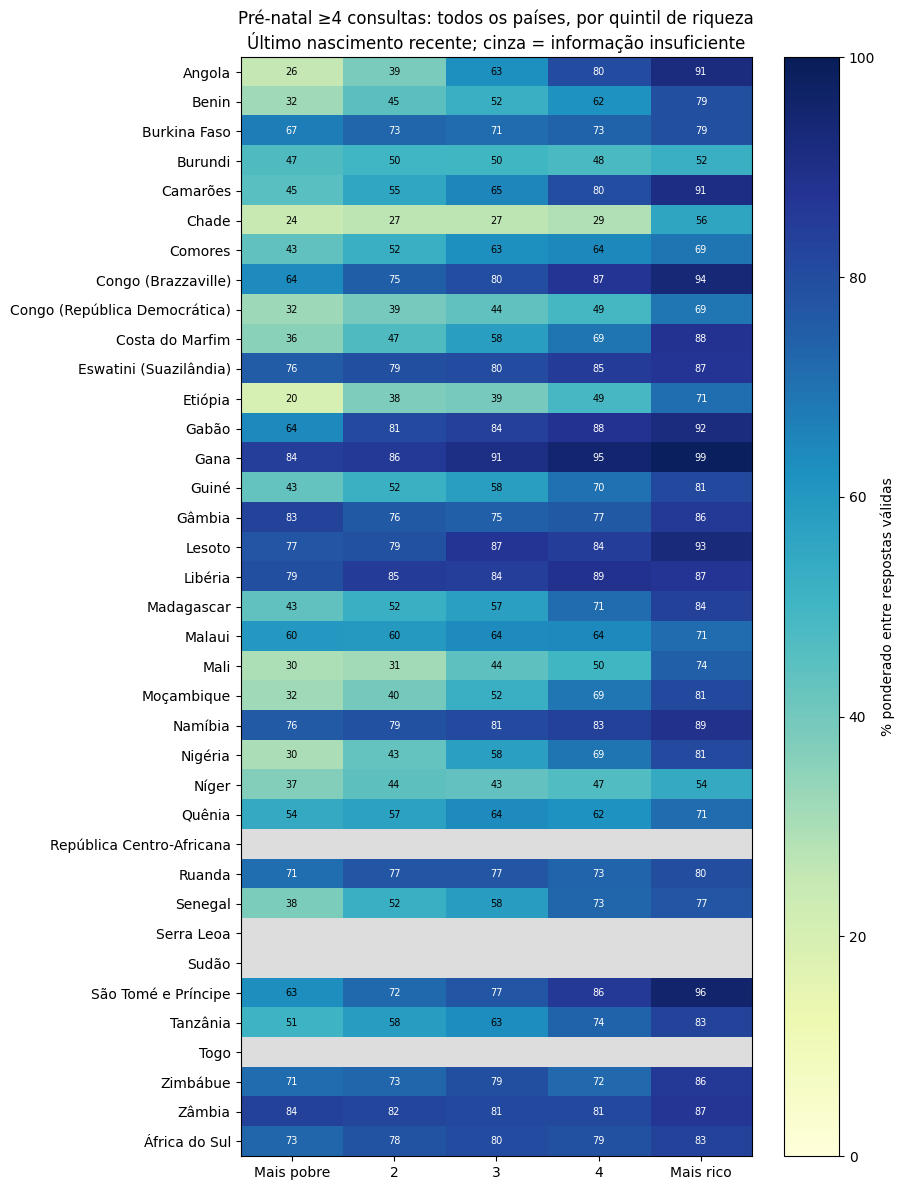

riqueza,1,5,diferenca_pp
nome,,,
Zâmbia,83.58,86.76,3.18
Gâmbia,82.76,85.97,3.21
Burundi,47.07,52.18,5.11
Libéria,79.01,87.36,8.35
Ruanda,70.79,79.67,8.88
África do Sul,72.95,82.56,9.62
Malaui,60.07,71.20,11.12
Eswatini (Suazilândia),75.76,87.41,11.65
Burkina Faso,67.28,79.17,11.88


,n_validos,nascimentos_recentes,cobertura_pct
nome,,,
Angola,5857,7825,74.85
Benin,8750,8977,97.47
Burkina Faso,6384,9292,68.70
Burundi,8634,8639,99.94
Camarões,2324,3085,75.33
Chade,10928,11104,98.41
Comores,1730,2016,85.81
Congo (Brazzaville),6429,6463,99.47
Congo (República Democrática),12241,15064,81.26


**Achado:** em 33 dos 33 países com pelo menos 30 respostas nos dois quintis extremos, o quintil mais rico apresenta maior percentual de quatro consultas. A diferença varia de 3.2 a 65.7 pontos percentuais. Países e estratos com baixa cobertura não devem ser ordenados como se o indicador tivesse a mesma completude em todos eles.

In [27]:
# Gradiente de pré-natal por país e riqueza, sem misturar pesos de países diferentes.
prenatal=r10.groupby(['codigo','nome','riqueza'],as_index=False)[['nascimentos_recentes','n_validos','peso_valido','peso_quatro_mais']].sum()
prenatal['percentual']=100*prenatal.peso_quatro_mais/prenatal.peso_valido.replace(0,np.nan)
prenatal['cobertura_pct']=100*prenatal.n_validos/prenatal.nascimentos_recentes
# Transparência: células com menos de 30 respostas não são comparadas no mapa.
prenatal.loc[prenatal.n_validos<30,'percentual']=np.nan
matriz=prenatal.pivot(index='nome',columns='riqueza',values='percentual').reindex(cobertura.nome.drop_duplicates().sort_values())
assert matriz.index.is_unique and len(matriz)==cobertura.codigo.nunique()
fig,ax=plt.subplots(figsize=(9,12))
cmap=plt.get_cmap('YlGnBu').copy(); cmap.set_bad('#dddddd')
im=ax.imshow(matriz.to_numpy(),vmin=0,vmax=100,cmap=cmap,aspect='auto')
ax.set_yticks(np.arange(len(matriz)),matriz.index); ax.set_xticks(np.arange(5),['Mais pobre','2','3','4','Mais rico'])
for row in range(len(matriz)):
    for col in range(5):
        value=matriz.iloc[row,col]
        if pd.notna(value): ax.text(col,row,f'{value:.0f}',ha='center',va='center',fontsize=7,color='white' if value>65 else 'black')
ax.set_title('Pré-natal ≥4 consultas: todos os países, por quintil de riqueza\nÚltimo nascimento recente; cinza = informação insuficiente')
fig.colorbar(im,ax=ax,label='% ponderado entre respostas válidas'); fig.tight_layout(); display(fig); plt.close(fig)
gradiente=matriz[[1,5]].dropna().copy(); gradiente['diferenca_pp']=gradiente[5]-gradiente[1]
display(gradiente.sort_values('diferenca_pp').round(2))
coverage=prenatal.groupby('nome')[['n_validos','nascimentos_recentes']].sum()
coverage['cobertura_pct']=100*coverage.n_validos/coverage.nascimentos_recentes
display(coverage.round(2))
display(Markdown(f"**Achado:** em {int((gradiente.diferenca_pp>0).sum())} dos {len(gradiente)} países com pelo menos 30 respostas nos dois quintis extremos, o quintil mais rico apresenta maior percentual de quatro consultas. A diferença varia de {gradiente.diferenca_pp.min():.1f} a {gradiente.diferenca_pp.max():.1f} pontos percentuais. Países e estratos com baixa cobertura não devem ser ordenados como se o indicador tivesse a mesma completude em todos eles."))

**Interpretação conjunta e inovação social:** as tabelas e gráficos mostram que território, riqueza e escolaridade precisam ser analisados conjuntamente. Uma diferença rural pequena pode coexistir com baixo uso nas duas áreas; uma grande vantagem urbana pode diminuir quando comparamos perfis socioeconômicos semelhantes. Para priorização, é necessário examinar simultaneamente o nível do indicador, o gradiente, o tamanho da amostra e a cobertura. Conhecimento sem uso não comprova falta de acesso, e mais consultas não comprova qualidade clínica.

Os resultados indicam hipóteses para ações e pesquisa — ampliar acesso rural, informação e condições materiais conforme o contexto — mas não identificam políticas públicas bem-sucedidas sem séries temporais, desenho causal e evidência externa. Essa distinção mantém as descobertas úteis e verificáveis.

**Uso social dos achados:** países com reversão da diferença territorial precisam de diagnóstico por composição socioeconômica; aqueles com grande distância entre conhecimento e uso exigem investigar preferências, demanda não atendida e barreiras de acesso. A distância não mede, sozinha, falta de autonomia. Células sem dados orientam a melhoria da coleta, e não a classificação de territórios como saudáveis. A seleção de políticas eficazes requer avaliação adicional; o banco fornece prioridades e hipóteses.


## 6.6 Otimização — ponto extra de até 20%

**Estratégia:** índice composto de filtro e cobertura em Entrevista para recuperar respostas positivas/negativas em um ano de entrevista, com a chave de junção no mesmo índice. A consulta seleciona o ano mais frequente do conjunto completo e cruza os países; o filtro tem uma razão analítica: comparar pesquisas de um mesmo período em vez de tratar anos diferentes como simultâneos.

Comparamos o **mesmo SQL, dados e resultado** antes e depois do índice. Fazemos uma execução de aquecimento e sete medições completas (`fetchall`) em cada versão; usamos a mediana. Mantemos cache e ambiente como limitações, mostramos as medidas individuais e os planos `EXPLAIN QUERY PLAN`. Os índices de PK/FK permanecem nas duas versões; não removemos integridade para produzir ganho artificial. A execução repetida remove somente o índice experimental no banco derivado.

In [28]:
conn.execute('DROP INDEX IF EXISTS idx_entrevista_ano_uso')
ano=conn.execute('SELECT ano FROM Entrevista WHERE ano IS NOT NULL GROUP BY ano ORDER BY COUNT(*) DESC LIMIT 1').fetchone()[0]
sql_otimizacao="""
SELECT p.nome,m.escolaridade,COUNT(*) AS n,SUM(e.peso) AS peso
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.ano=? AND e.usa_metodo=1
GROUP BY p.nome,m.escolaridade ORDER BY p.nome,m.escolaridade
"""
def medir():
    esperado=conn.execute(sql_otimizacao,(ano,)).fetchall() # aquecimento
    tempos=[]
    for _ in range(7):
        t=perf_counter(); obtido=conn.execute(sql_otimizacao,(ano,)).fetchall(); tempos.append(perf_counter()-t)
        assert obtido==esperado
    return esperado,tempos
antes,tempos_antes=medir()
plano_antes=pd.read_sql_query('EXPLAIN QUERY PLAN '+sql_otimizacao,conn,params=(ano,))
t=perf_counter()
conn.execute('CREATE INDEX idx_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso)')
conn.commit(); custo_indice=perf_counter()-t
depois,tempos_depois=medir()
plano_depois=pd.read_sql_query('EXPLAIN QUERY PLAN '+sql_otimizacao,conn,params=(ano,))
assert antes==depois, 'A otimização deve preservar os resultados.'
assert any('idx_entrevista_ano_uso' in str(x) for x in plano_depois.detail)
display(Markdown(f'**Ano filtrado: {ano}. Plano antes:**')); display(plano_antes)
display(Markdown('**Plano depois:**')); display(plano_depois)
display(pd.DataFrame({'execucao':range(1,8),'antes_ms':np.array(tempos_antes)*1000,'depois_ms':np.array(tempos_depois)*1000}))
med_antes,med_depois=median(tempos_antes),median(tempos_depois)
ganho=100*(1-med_depois/med_antes)
display(Markdown(f"**Resultado medido:** mediana de {med_antes*1000:.2f} ms antes e {med_depois*1000:.2f} ms depois; redução de {ganho:.1f}% e razão de {med_antes/med_depois:.2f}×. Criar o índice custou {custo_indice:.2f} s. O índice acelera este filtro, ocupa espaço e adiciona custo à carga; o ganho não vale automaticamente para todas as dez consultas."))
conn.execute('ANALYZE'); conn.commit()
print('Banco derivado final com índice e estatísticas; resultados equivalentes confirmados.')

**Ano filtrado: 2024. Plano antes:**

,id,parent,notused,detail
0,15,0,216,SCAN e
1,21,0,47,SEARCH m USING INDEX sqlite_autoindex_Mulher_1...
2,27,0,46,SEARCH d USING INDEX sqlite_autoindex_Domicili...
3,32,0,47,SEARCH l USING INDEX sqlite_autoindex_Levantam...
4,37,0,47,SEARCH p USING INDEX sqlite_autoindex_Pais_1 (...
5,42,0,0,USE TEMP B-TREE FOR GROUP BY


**Plano depois:**

,id,parent,notused,detail
0,15,0,55,SEARCH e USING COVERING INDEX idx_entrevista_a...
1,22,0,47,SEARCH m USING INDEX sqlite_autoindex_Mulher_1...
2,28,0,46,SEARCH d USING INDEX sqlite_autoindex_Domicili...
3,33,0,47,SEARCH l USING INDEX sqlite_autoindex_Levantam...
4,38,0,47,SEARCH p USING INDEX sqlite_autoindex_Pais_1 (...
5,43,0,0,USE TEMP B-TREE FOR GROUP BY


,execucao,antes_ms,depois_ms
0,1,82.0122,47.6691
1,2,81.4549,46.3596
2,3,81.7490,46.3722
3,4,81.1752,46.8902
4,5,84.1194,47.5350
5,6,80.0677,47.4750
6,7,82.7206,47.7449


**Resultado medido:** mediana de 81.75 ms antes e 47.47 ms depois; redução de 41.9% e razão de 1.72×. Criar o índice custou 0.42 s. O índice acelera este filtro, ocupa espaço e adiciona custo à carga; o ganho não vale automaticamente para todas as dez consultas.

Banco derivado final com índice e estatísticas; resultados equivalentes confirmados.


## 6.7 Verificação dos requisitos

| Critério | Evidência neste notebook |
|---|---|
| Tema de saúde da mulher — extra | IR, contracepção, desigualdades e pré-natal |
| Origem não SQL e reprodução | Stata DHS, portal/API, catálogo, manifesto e scripts — seção 3 |
| Processo bottom-up e normalização | Dependências funcionais, decomposição e carga executável — seção 3 |
| ≥4 entidades com identificador e ≥2 atributos | Levantamento, Domicilio, Mulher, Nascimento, Crianca, Metodo |
| ≥3 relacionamentos, incluindo M:N | FKs dos diagramas e Conhecimento_Metodo carregado e validado |
| Diagramas anexados | Imagens incorporadas nas seções 4 e 5 |
| 2 seleção/projeção | Consultas 1–2 |
| 3 junções de duas relações | Consultas 3–5 |
| 3 junções de três ou mais relações | Consultas 6–8 |
| 2 agregações sobre junções | Consultas 9–10 |
| Análise e gráficos | Cobertura, níveis, gradientes e padronização em todos os países — seção 6.5 |
| Otimização — extra de até 20% | Índice, planos, tempos repetidos e equivalência — seção 6.6 |
| Autoavaliação individual | Campos abaixo, a serem preenchidos pelos integrantes |

A pontuação depende da avaliação e apresentação; as evidências acima demonstram a implementação, sem garantir a nota. Os demais dois pontos de exercícios/participação dependem das atividades da disciplina e não podem ser produzidos ou comprovados por este notebook.

# 7. Autoavaliação dos membros

Por decisão do grupo nesta conversa, as atividades individuais permanecem pendentes até confirmação dos integrantes.

| Membro | Atividades realizadas | Autoavaliação |
|---|---|---|
| Henrique Lima Gusmão | A informar pelo integrante | A preencher |
| Felipe Pires Franco | A informar pelo integrante | A preencher |
| Izabella Galdino Correia | A informar pelo integrante | A preencher |
| Alice Lina Oliveira da Silva | A informar pelo integrante | A preencher |

Antes da entrega: completar as três matrículas faltantes, atividades e autoavaliações; revisar coletivamente interpretações e exportar o notebook para PDF. Todos devem participar da apresentação de até seis minutos.

In [29]:
assert set(cobertura.codigo)=={r[0] for r in conn.execute('SELECT codigo FROM Pais')}
for numero in range(1,11):
    tabela=globals()[f'r{numero}']
    assert len(tabela)>0, f'Consulta {numero} deve retornar dados.'
    coluna='pais_codigo' if numero<=5 else 'codigo'
    assert tabela[coluna].nunique()>1, f'Consulta {numero} deve abranger vários países.'
assert set(r3.pais_codigo)==set(cobertura.codigo)-{'SD'}, 'Sudão não possui residência disponível neste recorte.'
assert len(ajustes)>1 and len(prenatal)>1
print('Dez consultas validadas, comparação nacional de 37 países e análises ajustadas com cobertura explícita.')

assert set(panorama.codigo)==set(cobertura.codigo)
assert set(r8.codigo)==set(cobertura.codigo)
assert r9.codigo.nunique()==35


Dez consultas validadas, comparação nacional de 37 países e análises ajustadas com cobertura explícita.


In [30]:
conn.close()
assert sha256(origem)==hash_origem
print('Execução finalizada: origem preservada e banco normalizado salvo.')

Execução finalizada: origem preservada e banco normalizado salvo.
